# <center>**PIETRO SCAPINI - 513351 - Develop Churn Model**</center>
### <center>Lab exam</center>

<center>Pietro Scapini</center>

<center>24 June 2025</center>

The dataset provided contains transictional data, with coloumns representing:




| Attribute ID | Attribute                  | Attribute Description                                          |
|:------------:|:---------------------------|:---------------------------------------------------------------|
|1   		   | CustomerID                 | Unique customer ID.                                            |
|2   		   | Churn                      | Churn Flag.                                                    |
|3   		   | Tenure                     | Tenure of customer in organization.                            |
|4   		   | PreferredLoginDevice       | Preferred login device of customer.                            |
|5   		   | CityTier                   | City tier.                                                     |
|6   		   | WarehouseToHome            | Distance in between warehouse to home of customer.             |
|7   		   | PreferredPaymentMode       | Preferred payment method of customer.                          |
|8   		   | Gender                     | Gender of customer.                                            |
|9   		   | HourSpendOnApp             | Number of hours spend on mobile application or website.        |
|10  		   | NumberOfDeviceRegistered   | Total number of deceives is registered on particular customer. |
|11  		   | PreferedOrderCat           | Preferred order category of customer in last month.            |
|12  		   | SatisfactionScore          | Satisfactory score of customer on service.                     |
|13  		   | MaritalStatus              | Marital status of customer.                                    |
|14  		   | NumberOfAddress            | Total number of added added on particular customer.            |
|15  		   | Complain                   | Any complaint has been raised in last month.                   |
|16  		   | OrderAmountHikeFromlastYear| Percentage increases in order from last year.                  |
|17  		   | CouponUsed                 | Total number of coupon has been used in last month.            |
|18  		   | OrderCount                 | Total number of orders has been places in last month.          |
|19  		   | DaySinceLastOrder          | Day Since last order by customer.                              |
|20  		   | CashbackAmount             | Average cashback in last month.                                |


## **DATA PREPARATION and EXPLORATION**

### PREPROCESSING

In the initial phase, the dataset is downloaded and explored to understand its structure. This involves reviewing the features and identifying any missing values, which helps guide the next steps of data cleaning and preparation.

In [ ]:
!pip uninstall -y scikit-learn
!pip install scikit-learn==1.5.2

Found existing installation: scikit-learn 1.5.2
Uninstalling scikit-learn-1.5.2:
  Successfully uninstalled scikit-learn-1.5.2
  Using cached scikit_learn-1.5.2-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (13 kB)
Using cached scikit_learn-1.5.2-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (13.3 MB)


In [ ]:
!pip install scikeras -qq
!pip install tensorflow -qq

In [ ]:
pip install catboost -qq

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score, roc_curve, roc_auc_score, recall_score, precision_score
from sklearn.inspection import permutation_importance

from imblearn.over_sampling import SMOTE

from scikeras.wrappers import KerasClassifier
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam




In [ ]:
df_raw = pd.read_excel('/content/data.xlsx')

In [ ]:
df_raw.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001.0,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002.0,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003.0,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004.0,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005.0,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [ ]:
df_raw.shape

(5630, 20)

In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5628 non-null   float64
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5628 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   object 
 13  NumberOfAddress   

<Axes: >

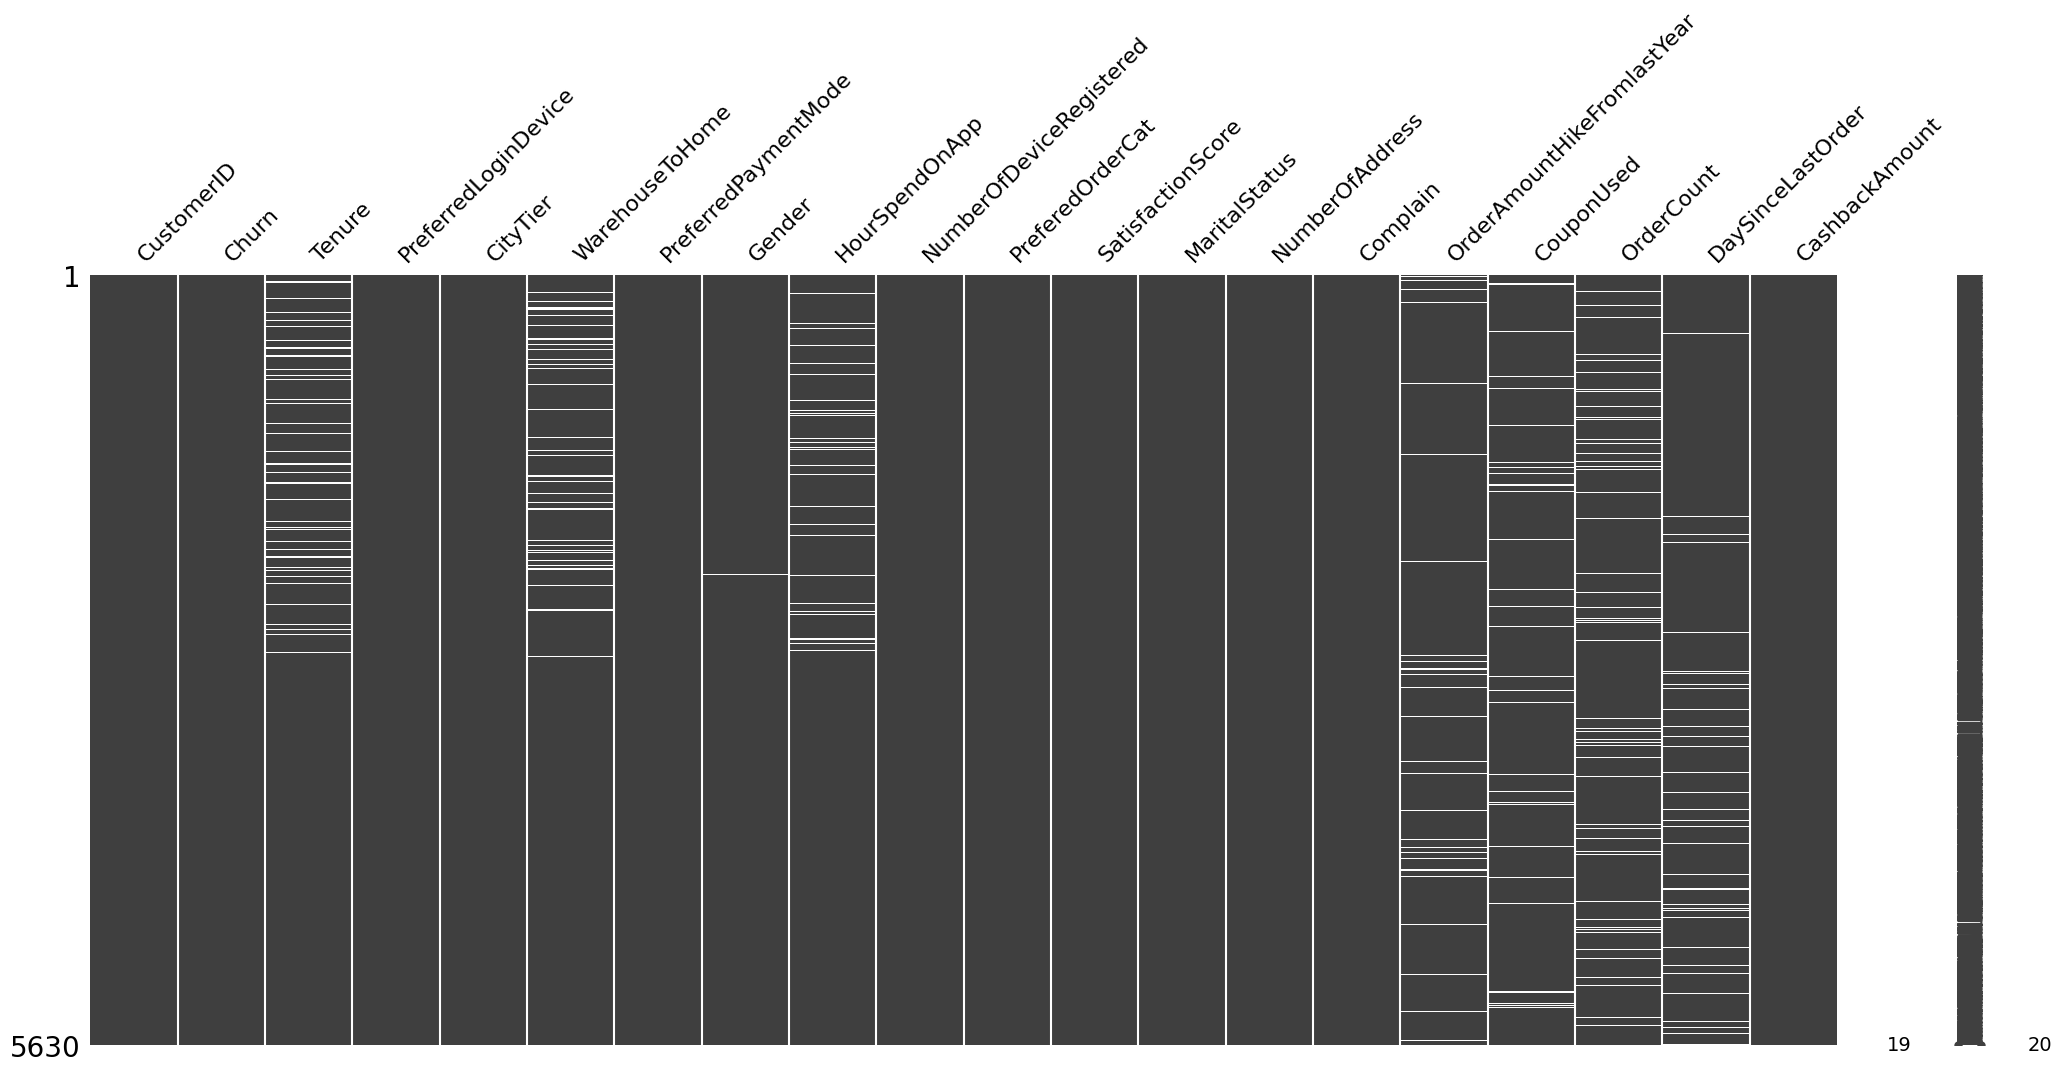

In [ ]:
msno.matrix(df_raw)

In [ ]:
df_raw.isnull().sum()

,0
CustomerID,2
Churn,0
Tenure,264
PreferredLoginDevice,0
CityTier,0
WarehouseToHome,251
PreferredPaymentMode,0
Gender,2
HourSpendOnApp,255
NumberOfDeviceRegistered,0


In [ ]:
df_raw.describe()

,CustomerID,Churn,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
count,5628.000000,5630.000000,5366.000000,5630.000000,5379.000000,5375.000000,5630.000000,5630.000000,5630.000000,5630.000000,5365.000000,5374.000000,5372.000000,5323.000000,5630.000000
mean,52814.549041,0.168384,10.189899,1.654707,15.639896,2.931535,3.688988,3.066785,4.214032,0.284902,15.707922,1.751023,3.008004,4.543491,532.401057
std,1624.890759,0.374240,8.557241,0.915389,8.531475,0.721926,1.023999,1.380194,2.583586,0.451408,3.675485,1.894621,2.939680,3.654433,18842.837049
min,50001.000000,0.000000,0.000000,1.000000,5.000000,0.000000,1.000000,1.000000,1.000000,0.000000,11.000000,0.000000,1.000000,0.000000,0.000000
25%,51407.750000,0.000000,2.000000,1.000000,9.000000,2.000000,3.000000,2.000000,2.000000,0.000000,13.000000,1.000000,1.000000,2.000000,145.770000
50%,52814.500000,0.000000,9.000000,1.000000,14.000000,3.000000,4.000000,3.000000,3.000000,0.000000,15.000000,1.000000,2.000000,3.000000,163.330000
75%,54221.250000,0.000000,16.000000,3.000000,20.000000,3.000000,4.000000,4.000000,6.000000,1.000000,18.000000,2.000000,3.000000,7.000000,196.422500
max,55630.000000,1.000000,61.000000,3.000000,127.000000,5.000000,6.000000,5.000000,22.000000,1.000000,26.000000,16.000000,16.000000,46.000000,999999.000000


In [ ]:
print(df_raw.duplicated().sum())

0


### DATA CLEANING

Missing values are handled using suitable imputation strategies, chosen according to the characteristics of each feature.


Various methods were used to manage null values, selected with the aim of maintaining the same distribution before and after the cleaning operation.

In [ ]:
df_clean = df_raw.copy()

#### CustomerID

`CustomerID` is a unique identifier that does not provide useful information for predicting churn. Since the model to be developed will be applied to known customers, this feature must be excluded to avoid overfitting and improve generalisation.

In [ ]:
df_clean = df_clean.drop('CustomerID', axis=1)

#### Gender

Since there are only a few missing values, we choose to remove them directly

In [ ]:
df_clean.dropna(subset=['Gender'], inplace=True)

#### Tenure

BEFORE CLEANING

<Axes: xlabel='Tenure', ylabel='Density'>

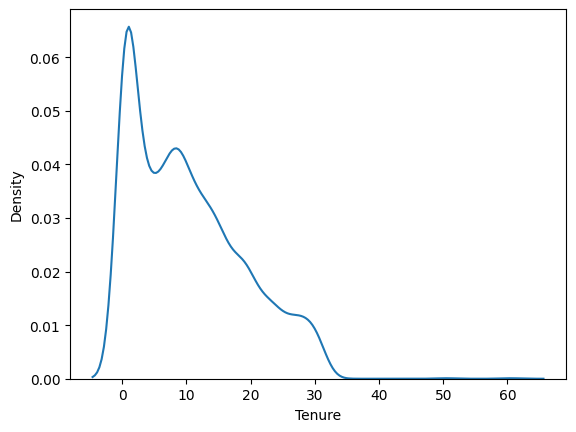

In [ ]:
sns.kdeplot(df_clean , x='Tenure')

In [ ]:
s_imp = SimpleImputer(missing_values=np.nan , strategy = 'most_frequent')
df_clean['Tenure'] = s_imp.fit_transform(pd.DataFrame(df_clean['Tenure']))

AFTER CLEANING

<Axes: xlabel='Tenure', ylabel='Density'>

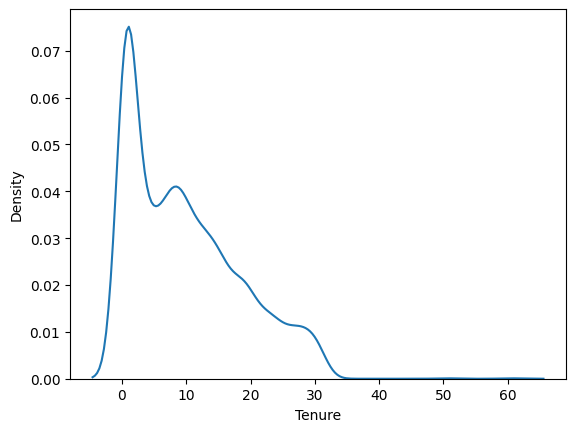

In [ ]:
sns.kdeplot(df_clean , x='Tenure')

#### WarehouseToHome

BEFORE CLEANING

<Axes: xlabel='WarehouseToHome', ylabel='Density'>

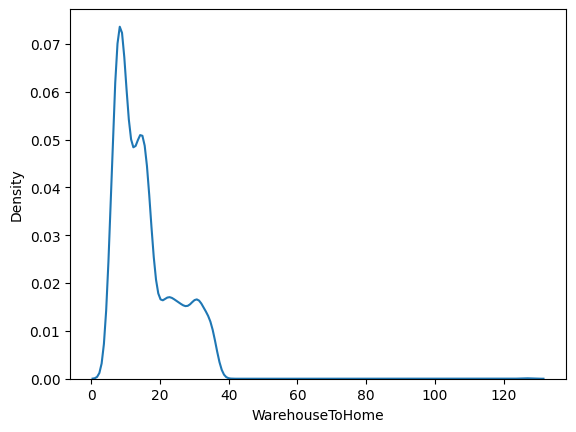

In [ ]:
sns.kdeplot(df_clean , x='WarehouseToHome')

In [ ]:
s_imp = SimpleImputer(missing_values=np.nan , strategy = 'most_frequent')
df_clean['WarehouseToHome'] = s_imp.fit_transform(pd.DataFrame(df_clean['WarehouseToHome']))

AFTER CLEANING

<Axes: xlabel='WarehouseToHome', ylabel='Density'>

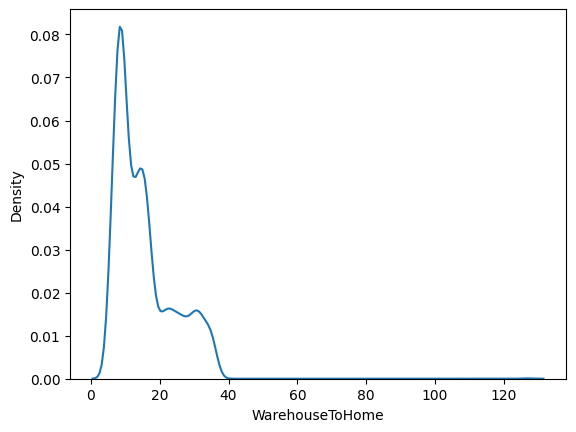

In [ ]:
sns.kdeplot(df_clean , x='WarehouseToHome')

#### HourSpendOnApp

The chart shows four groups that appear to be associated with `PreferredLoginDevice`. Based on this observation, the missing values in `HourSpendOnApp` are filled by calculating the median within each `PreferredLoginDevice` group, preserving the relationship between the variables.

BEFORE CLEANING

<Axes: xlabel='HourSpendOnApp', ylabel='Density'>

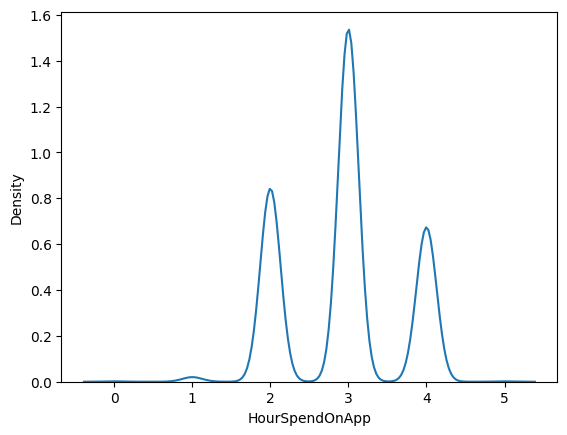

In [ ]:
sns.kdeplot(df_clean , x='HourSpendOnApp')

In [ ]:
df_clean['HourSpendOnApp'] = df_clean.groupby('PreferredLoginDevice')['HourSpendOnApp'].transform(lambda x: x.fillna(x.median()))


AFTER CLEANING

<Axes: xlabel='HourSpendOnApp', ylabel='Density'>

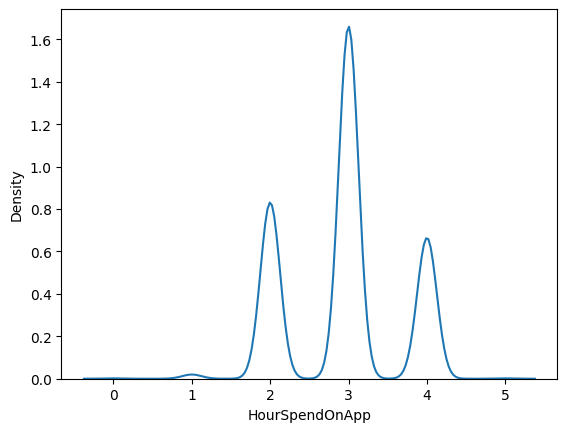

In [ ]:
sns.kdeplot(df_clean , x='HourSpendOnApp')

#### OrderAmountHikeFromlastYear

BEFORE CLEANING

<Axes: xlabel='OrderAmountHikeFromlastYear', ylabel='Density'>

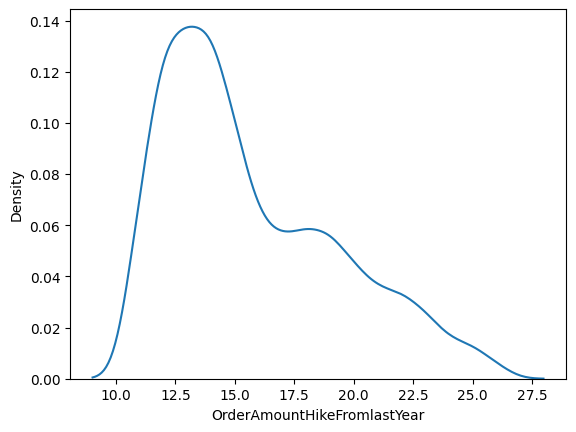

In [ ]:
sns.kdeplot(df_clean , x='OrderAmountHikeFromlastYear')

In [ ]:
# Fill with the previous non-null value --> useful for time-ordered data
df_clean['OrderAmountHikeFromlastYear'] = df_clean['OrderAmountHikeFromlastYear'].fillna(method='ffill')

/tmp/ipython-input-107-4292243671.py:2: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_clean['OrderAmountHikeFromlastYear'] = df_clean['OrderAmountHikeFromlastYear'].fillna(method='ffill')


AFTER CLEANING

<Axes: xlabel='OrderAmountHikeFromlastYear', ylabel='Density'>

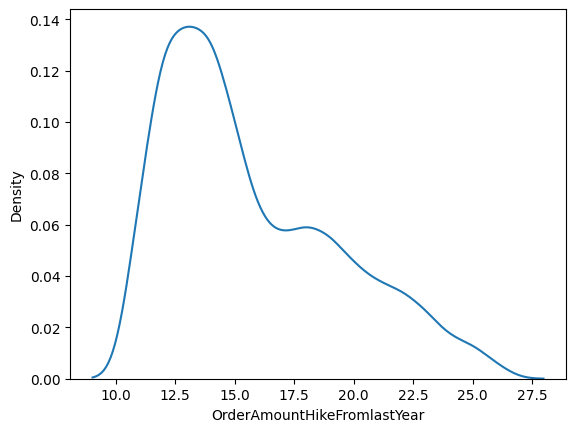

In [ ]:
sns.kdeplot(df_clean , x='OrderAmountHikeFromlastYear')

#### CouponUsed

BEFORE CLEANING

<Axes: xlabel='CouponUsed', ylabel='Density'>

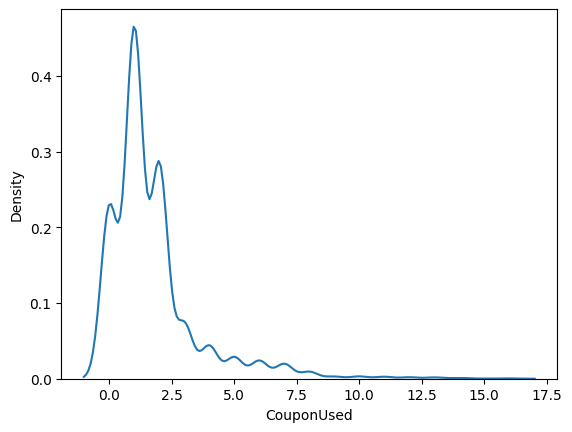

In [ ]:
sns.kdeplot(df_clean , x='CouponUsed')

In [ ]:
imputer = KNNImputer(n_neighbors=2)
df_clean['CouponUsed']=imputer.fit_transform(df_clean[['CouponUsed']])

AFTER CLEANING

<Axes: xlabel='CouponUsed', ylabel='Density'>

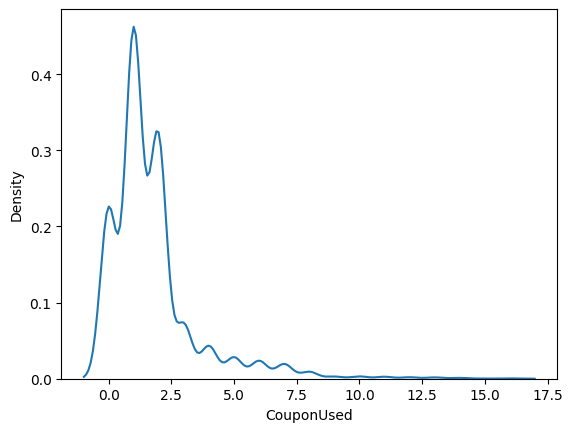

In [ ]:
sns.kdeplot(df_clean , x='CouponUsed')

#### OrderCount

BEFORE CLEANING

<Axes: xlabel='OrderCount', ylabel='Density'>

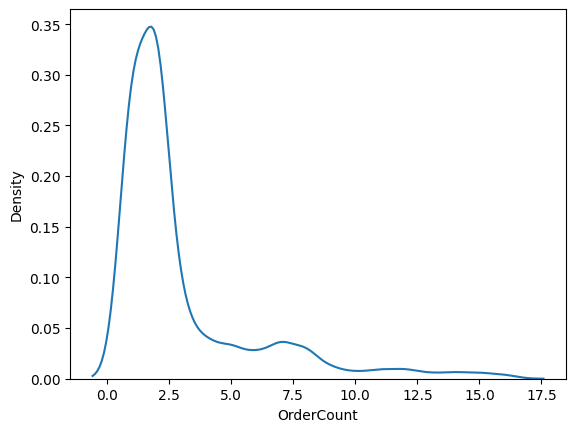

In [ ]:
sns.kdeplot(df_clean , x='OrderCount')

In [ ]:
imputer = KNNImputer(n_neighbors=2)
df_clean['OrderCount']=imputer.fit_transform(df_clean[['OrderCount']])

AFTER CLEANING

<Axes: xlabel='OrderCount', ylabel='Density'>

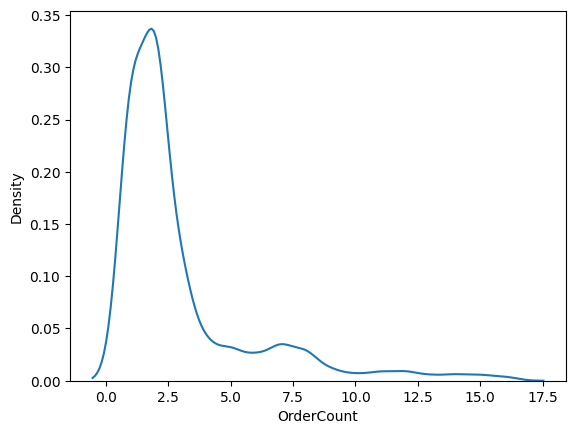

In [ ]:
sns.kdeplot(df_clean , x='OrderCount')

#### DaySinceLastOrder

BEFORE CLEANING

<Axes: xlabel='DaySinceLastOrder', ylabel='Density'>

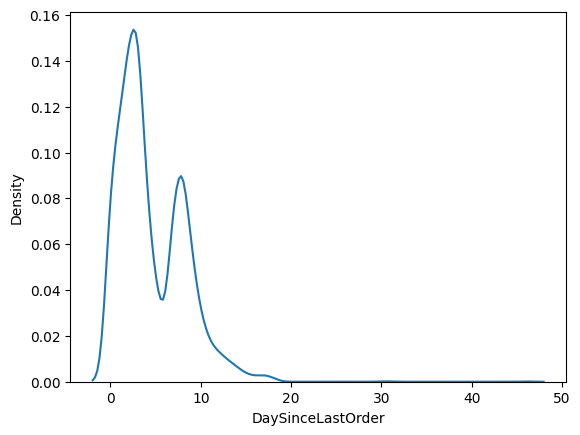

In [ ]:
sns.kdeplot(df_clean , x='DaySinceLastOrder')

In [ ]:
df_clean['DaySinceLastOrder'] = df_clean['DaySinceLastOrder'].fillna(df_clean['DaySinceLastOrder'].median())

AFTER CLEANING

<Axes: xlabel='DaySinceLastOrder', ylabel='Density'>

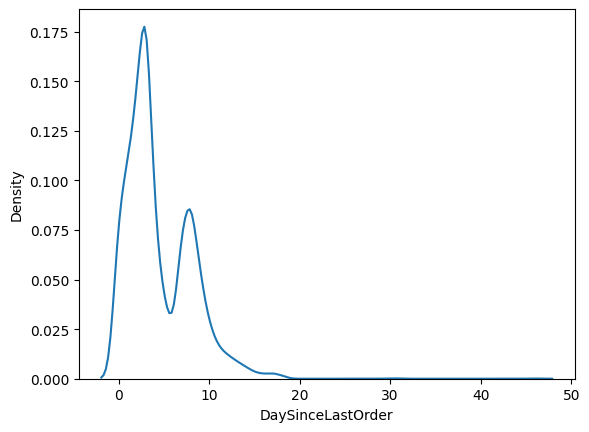

In [ ]:
sns.kdeplot(df_clean , x='DaySinceLastOrder')

#### **DATASET CLEAN**

In [ ]:
df_clean.isnull().sum()

,0
Churn,0
Tenure,0
PreferredLoginDevice,0
CityTier,0
WarehouseToHome,0
PreferredPaymentMode,0
Gender,0
HourSpendOnApp,0
NumberOfDeviceRegistered,0
PreferedOrderCat,0


### DATA TYPE CONVERSION

Identification of decimal values in numerical columns, with the exception of `CashbackAmount` for which decimal numbers are allowed, and conversion to integer numbers.
Variables (`CouponUsed`, `OrderCount`) that have decimal values are rounded and converted to integer numbers to ensure consistency in data management.


In [ ]:
df_typed = df_clean.copy()

In [ ]:
categorical_cols = (df_typed.dtypes[df_clean.dtypes == 'object'].index)
numerical_cols = (df_typed.dtypes[df_clean.dtypes != 'object'].index)

In [ ]:
df_typed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5628 entries, 0 to 5629
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Churn                        5628 non-null   int64  
 1   Tenure                       5628 non-null   float64
 2   PreferredLoginDevice         5628 non-null   object 
 3   CityTier                     5628 non-null   int64  
 4   WarehouseToHome              5628 non-null   float64
 5   PreferredPaymentMode         5628 non-null   object 
 6   Gender                       5628 non-null   object 
 7   HourSpendOnApp               5628 non-null   float64
 8   NumberOfDeviceRegistered     5628 non-null   int64  
 9   PreferedOrderCat             5628 non-null   object 
 10  SatisfactionScore            5628 non-null   int64  
 11  MaritalStatus                5628 non-null   object 
 12  NumberOfAddress              5628 non-null   int64  
 13  Complain               

In [ ]:
print("Before rounding and type conversion:")
for col in [c for c in numerical_cols if c != 'CashbackAmount']:
    has_decimals = (df_typed[col] % 1 != 0).any()
    print(f"{col}: {has_decimals}")
    if has_decimals:
        df_typed[col] = df_typed[col].round()
    df_typed[col] = df_typed[col].astype('int64')

print("\nAfter rounding and type conversion:")
for col in [c for c in numerical_cols if c != 'CashbackAmount']:
    has_decimals = (df_typed[col] % 1 != 0).any()
    print(f"{col}: {has_decimals}")


Before rounding and type conversion:
Churn: False
Tenure: False
CityTier: False
WarehouseToHome: False
HourSpendOnApp: False
NumberOfDeviceRegistered: False
SatisfactionScore: False
NumberOfAddress: False
Complain: False
OrderAmountHikeFromlastYear: False
CouponUsed: True
OrderCount: True
DaySinceLastOrder: False

After rounding and type conversion:
Churn: False
Tenure: False
CityTier: False
WarehouseToHome: False
HourSpendOnApp: False
NumberOfDeviceRegistered: False
SatisfactionScore: False
NumberOfAddress: False
Complain: False
OrderAmountHikeFromlastYear: False
CouponUsed: False
OrderCount: False
DaySinceLastOrder: False


In [ ]:
df_typed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5628 entries, 0 to 5629
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Churn                        5628 non-null   int64  
 1   Tenure                       5628 non-null   int64  
 2   PreferredLoginDevice         5628 non-null   object 
 3   CityTier                     5628 non-null   int64  
 4   WarehouseToHome              5628 non-null   int64  
 5   PreferredPaymentMode         5628 non-null   object 
 6   Gender                       5628 non-null   object 
 7   HourSpendOnApp               5628 non-null   int64  
 8   NumberOfDeviceRegistered     5628 non-null   int64  
 9   PreferedOrderCat             5628 non-null   object 
 10  SatisfactionScore            5628 non-null   int64  
 11  MaritalStatus                5628 non-null   object 
 12  NumberOfAddress              5628 non-null   int64  
 13  Complain               

### OUTLIERS

Identification and removal of OUTLIERS present in certain numerical variables, taking care to preserve the structure of the dataset and with the goal of improving model performance.

In [ ]:
df_outlier = df_typed.copy()

#### Visualization of Outliers

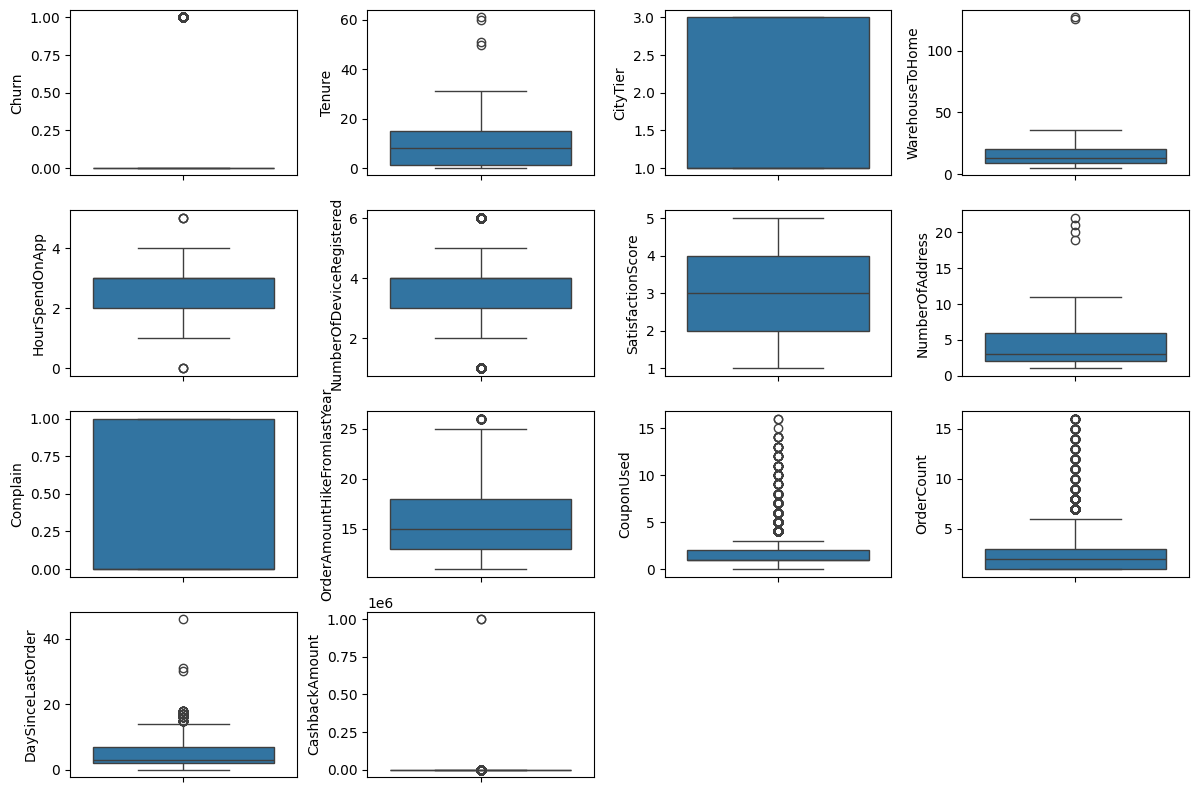

In [ ]:
fig = plt.figure(figsize=(12,18))
for i, col in enumerate(numerical_cols):
    fig.add_subplot(9,4,i+1)
    sns.boxplot(y=df_outlier[col])
plt.tight_layout()
plt.show()

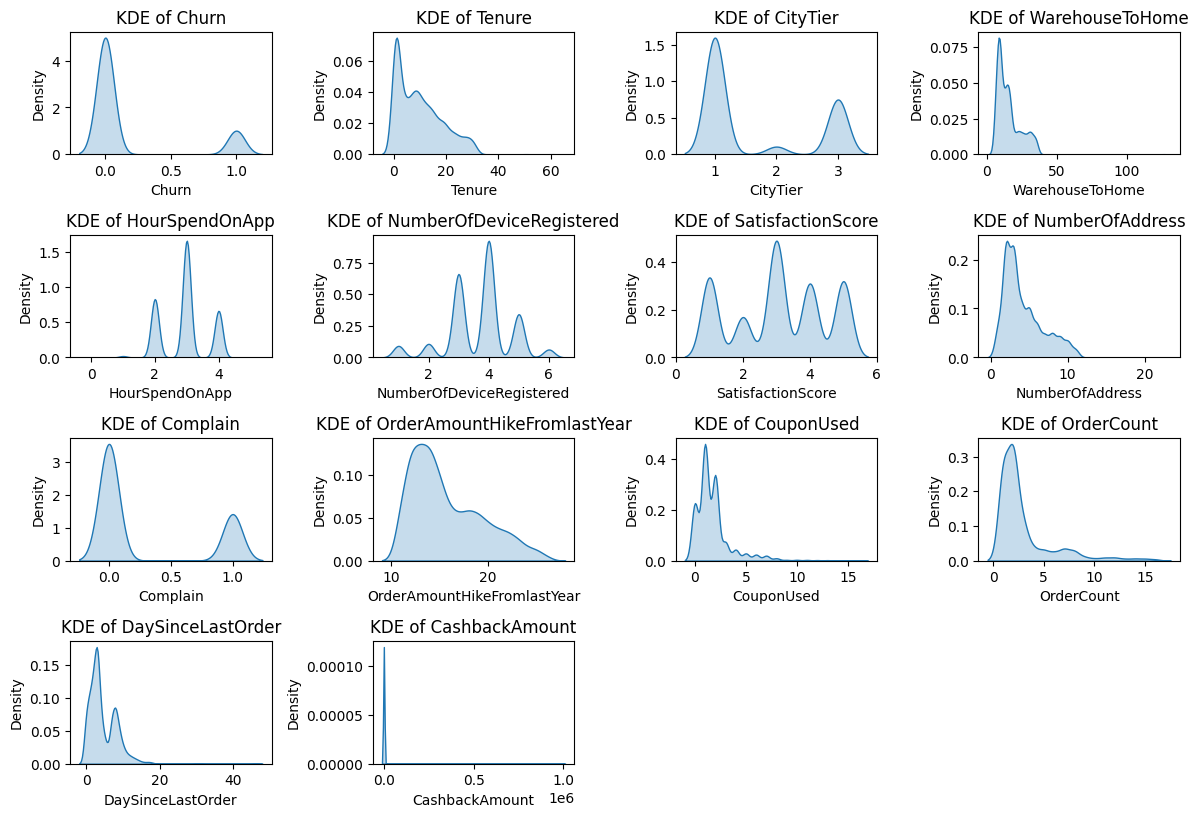

In [ ]:
fig = plt.figure(figsize=(12, 18))
for i, col in enumerate(numerical_cols):
    fig.add_subplot(9,4,i+1)
    sns.kdeplot(df_outlier[col], fill=True)
    plt.xlabel(col)
    plt.ylabel("Density")
    plt.title(f"KDE of {col}")
plt.tight_layout()
plt.show()


In [ ]:
df_outlier.describe(percentiles=[.01,.1,.25,.5,.75,.90,.95,.99]).T

,count,mean,std,min,1%,10%,25%,50%,75%,90%,95%,99%,max
Churn,5628.0,0.168443,0.374293,0.0,0.00,0.00,0.00,0.00,0.00,1.00,1.0000,1.0000,1.0
Tenure,5628.0,9.759595,8.578076,0.0,0.00,1.00,1.00,8.00,15.00,23.00,27.0000,30.0000,61.0
CityTier,5628.0,1.654584,0.915335,1.0,1.00,1.00,1.00,1.00,3.00,3.00,3.0000,3.0000,3.0
WarehouseToHome,5628.0,15.340796,8.449542,5.0,6.00,7.00,9.00,13.00,20.00,30.00,32.0000,35.0000,127.0
HourSpendOnApp,5628.0,2.934613,0.705652,0.0,2.00,2.00,2.00,3.00,3.00,4.00,4.0000,4.0000,5.0
NumberOfDeviceRegistered,5628.0,3.688877,1.024164,1.0,1.00,3.00,3.00,4.00,4.00,5.00,5.0000,6.0000,6.0
SatisfactionScore,5628.0,3.067164,1.380164,1.0,1.00,1.00,2.00,3.00,4.00,5.00,5.0000,5.0000,5.0
NumberOfAddress,5628.0,4.214463,2.583874,1.0,1.00,2.00,2.00,3.00,6.00,8.00,10.0000,11.0000,22.0
Complain,5628.0,0.284826,0.451372,0.0,0.00,0.00,0.00,0.00,1.00,1.00,1.0000,1.0000,1.0
OrderAmountHikeFromlastYear,5628.0,15.732054,3.689763,11.0,11.00,12.00,13.00,15.00,18.00,21.00,23.0000,25.0000,26.0


#### NumberOfAddress

In [ ]:
df_outlier['NumberOfAddress'].value_counts().sort_index()

,count
NumberOfAddress,
1,371
2,1368
3,1278
4,587
5,571
6,382
7,256
8,280
9,239


In [ ]:
df_outlier = df_outlier[~df_outlier['NumberOfAddress'].isin([19, 20, 21, 22])]

#### DaySinceLastOrder

In [ ]:
df_outlier['DaySinceLastOrder'].value_counts().sort_index()

,count
DaySinceLastOrder,
0,494
1,613
2,792
3,1206
4,429
5,228
6,113
7,447
8,538


In [ ]:
df_outlier = df_outlier[~df_outlier['DaySinceLastOrder'].isin([30, 31, 46])]

#### CashbackAmount

In [ ]:
df_outlier['CashbackAmount'].value_counts().sort_index()

,count
CashbackAmount,
0.00,4
12.00,1
25.00,4
37.00,1
56.00,1
...,...
324.26,2
324.43,2
324.73,2


In [ ]:
df_outlier = df_outlier[~df_outlier['CashbackAmount'].isin([999999])]

#### Visualizing Data After Outlier Treatment

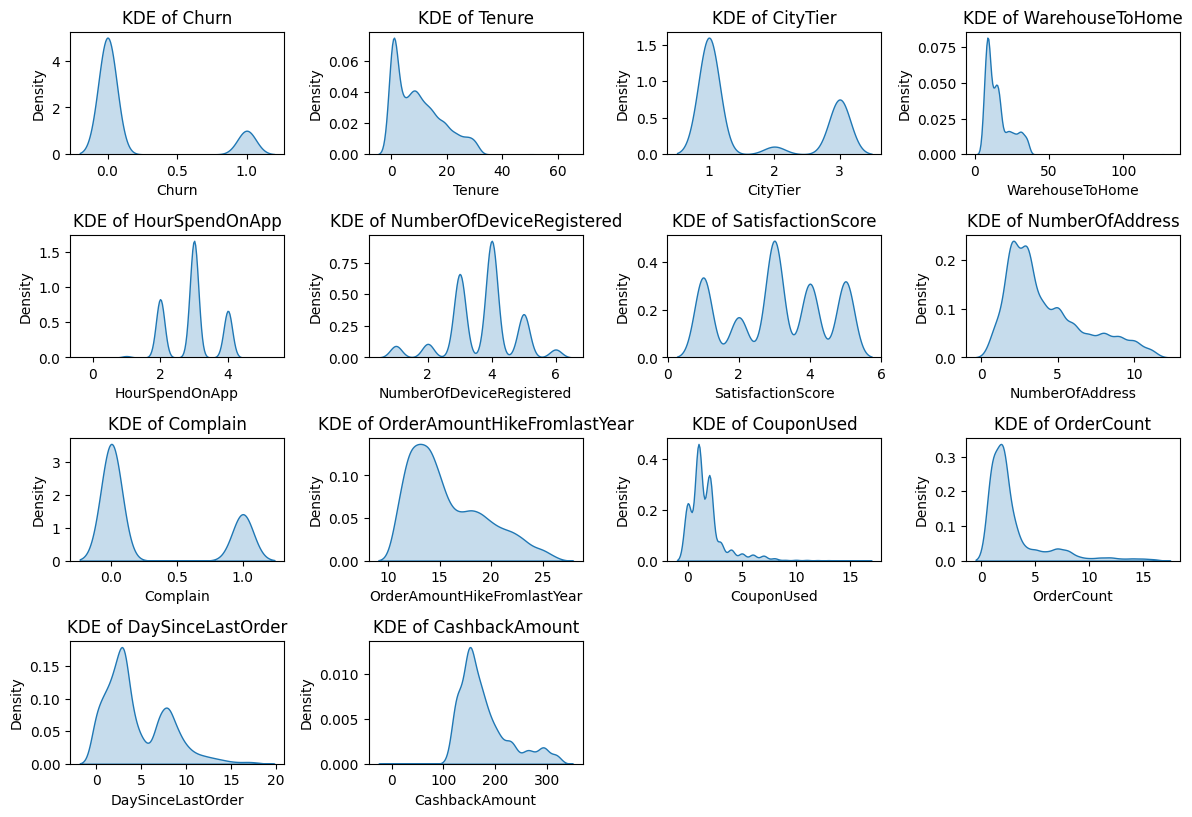

In [ ]:
fig = plt.figure(figsize=(12, 18))
for i, col in enumerate(numerical_cols):
    fig.add_subplot(9,4,i+1)
    sns.kdeplot(df_outlier[col], fill=True)
    plt.xlabel(col)
    plt.ylabel("Density")
    plt.title(f"KDE of {col}")
plt.tight_layout()
plt.show()

### EXPLORATIVE DATA ANALYSIS

Therefore, after the final step, the resulting EDA will appear as follows.

In [ ]:
df_eda = df_outlier.copy()

#### Categorical Variables Distribution

In [ ]:
for column in categorical_cols:
        print("Column: {} - Unique Values: {}".format(column, df_eda[column].unique()))
        print("")
        print("="*150)
        print("")

Column: PreferredLoginDevice - Unique Values: ['Mobile Phone' 'Phone' 'Computer' 'N.A.']


Column: PreferredPaymentMode - Unique Values: ['Debit Card' 'UPI' 'CC' 'Cash on Delivery' 'E wallet' 'COD' 'Credit Card']


Column: Gender - Unique Values: ['Female' 'Male']


Column: PreferedOrderCat - Unique Values: ['Laptop & Accessory' 'Mobile' 'Mobile Phone' 'Others' 'Fashion' 'Grocery']


Column: MaritalStatus - Unique Values: ['Single' 'Divorced' 'Married' 'Widow']




In [ ]:
def categorical_plot_count(df, column_name, color='skyblue', rotation_angle=45):

    counts = df[column_name].value_counts()

    fig, ax = plt.subplots()
    bars = ax.bar(counts.index, counts.values, color=color)

    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, height + 1, str(int(height)),
                ha='center', va='bottom')

    ax.set_ylabel('Count')
    ax.set_title(f'Histogram of {column_name.capitalize()}')

    plt.xticks(rotation=rotation_angle, ha='right')
    plt.tight_layout()
    plt.show()


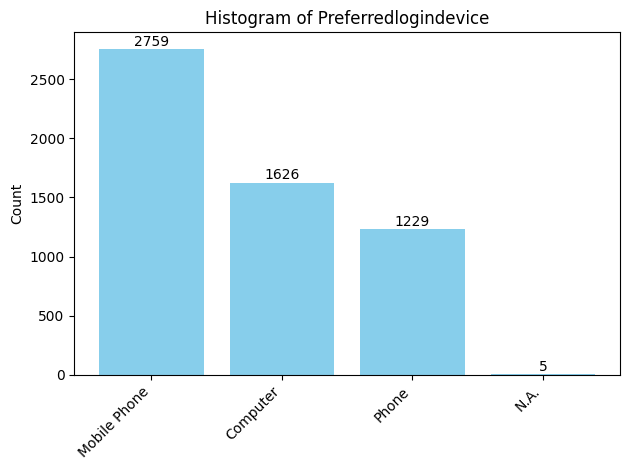

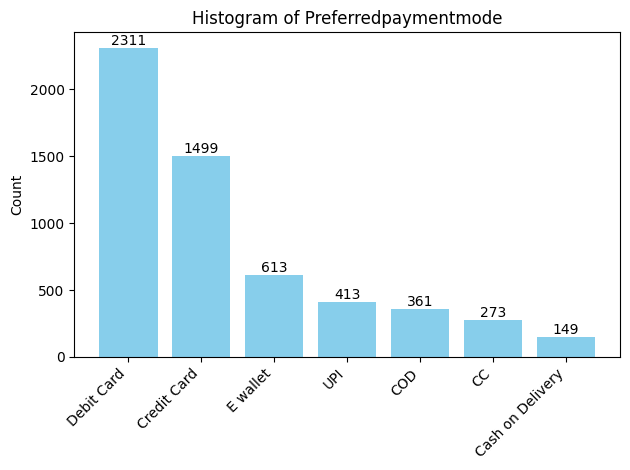

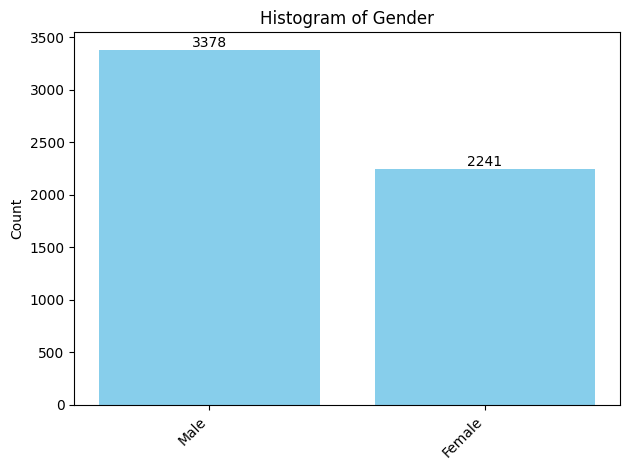

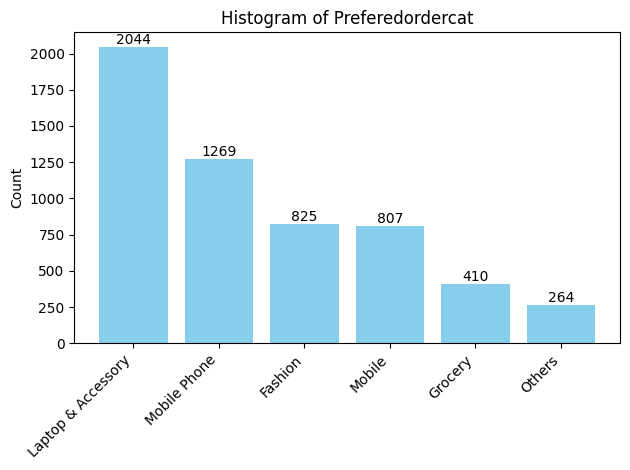

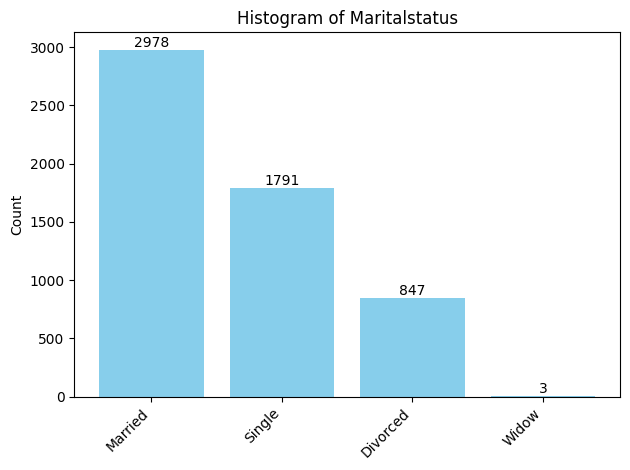

In [ ]:
for col in categorical_cols:
    categorical_plot_count(df_eda, col)

#### Correlation Matrix of numerical columns

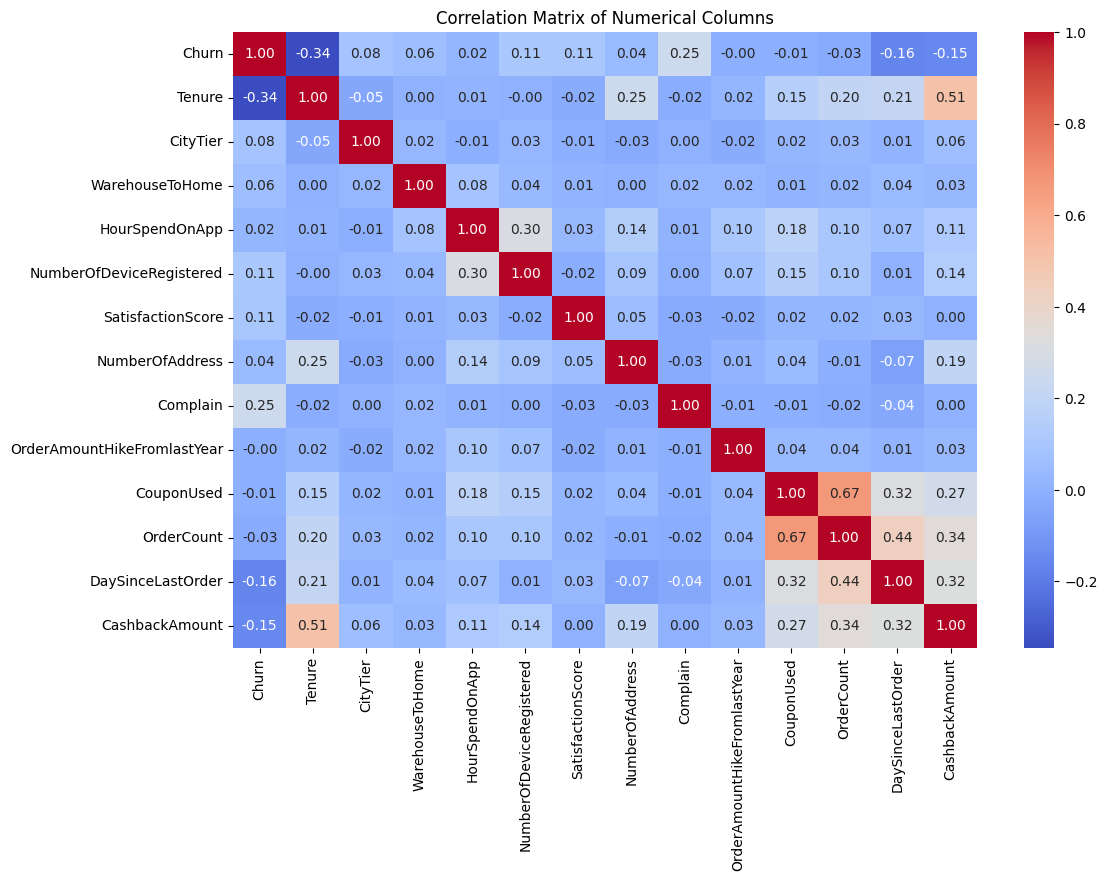

In [ ]:
df_numerical = df_eda[numerical_cols]

corr_numerical = df_numerical.corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr_numerical, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix of Numerical Columns")
plt.show()

## **CHURN MODEL**

In [ ]:
df_final = df_eda.copy()

### ONE-HOT ENCODING

One-hot encoding was performed in order to enable the use of SMOTE, which requires all variables to have numerical values. At the beginning of the process, categorical variables were kept as ‘strings’ to facilitate analysis and distribution (on EDA).

In [ ]:
df_final = pd.get_dummies(df_final, columns=categorical_cols, drop_first=False)
df_final = df_final.astype(int)

In [ ]:
df_final.head()

,Churn,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,...,PreferedOrderCat_Fashion,PreferedOrderCat_Grocery,PreferedOrderCat_Laptop & Accessory,PreferedOrderCat_Mobile,PreferedOrderCat_Mobile Phone,PreferedOrderCat_Others,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,MaritalStatus_Widow
0,1,4,3,6,3,3,2,9,1,11,...,0,0,1,0,0,0,0,0,1,0
1,1,1,1,8,3,4,3,7,1,15,...,0,0,0,1,0,0,0,0,1,0
2,1,1,1,30,2,4,3,6,1,14,...,0,0,0,1,0,0,0,0,1,0
3,1,0,3,15,2,4,5,8,0,23,...,0,0,1,0,0,0,0,0,1,0
4,1,0,1,12,3,3,5,3,0,11,...,0,0,0,1,0,0,0,0,1,0


In [ ]:
df_final.shape

(5619, 37)

### DATA PARTITIONING

In [ ]:
y = df_final['Churn']
X = df_final.drop(columns=['Churn'])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

#### Data Balancing (Churn)

The use of SMOTE at X_train was necessary to solve the problem of the ‘imbalance’ of the target variable Churn, thus ensuring that the model did not become biased towards the ‘dominant’ class.

In [ ]:
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("Shape of X_train before SMOTE:", X_train.shape)
print("Shape of y_train before SMOTE:", y_train.shape)
print("Shape of X_train after SMOTE:", X_train_resampled.shape)
print("Shape of y_train after SMOTE:", y_train_resampled.shape)

print("\nDistribution of target variable before SMOTE:")
print(y_train.value_counts())
print("\nDistribution of target variable after SMOTE:")
print(y_train_resampled.value_counts())

Shape of X_train before SMOTE: (4495, 36)
Shape of y_train before SMOTE: (4495,)
Shape of X_train after SMOTE: (7478, 36)
Shape of y_train after SMOTE: (7478,)

Distribution of target variable before SMOTE:
Churn
0    3739
1     756
Name: count, dtype: int64

Distribution of target variable after SMOTE:
Churn
0    3739
1    3739
Name: count, dtype: int64


In [ ]:
X_train, y_train = X_train_resampled, y_train_resampled

### Data Standardization Only for Logistic Regression and MLP

Data standardization was applied only to the **Logistic Regression** and **MLP** models using `StandardScaler`, as it is important for ensuring proper convergence and optimal performance in these cases. For the other models, scaling was not performed since it does not significantly affect their performance.

### FUNCTIONS FOR THE EVALUATION

#### Compute Scores

In [ ]:
list_scores = [roc_auc_score, recall_score, precision_score, accuracy_score]
score_names = ['roc_auc', 'recall', 'precision', 'accuracy']

def compute_scores(model, x_test, y_test, scores):
    y_pred = model.predict(x_test)
    y_proba = model.predict_proba(x_test)[:, 1]

    results = []
    for score in scores:
        if score == roc_auc_score:
            results.append(round(score(y_test, y_proba), 2))
        else:
            results.append(round(score(y_test, y_pred), 2))
    return results

#### Roc Curve

The ROC curve displays the performance of a binary classifier across different threshold settings by plotting the True Positive Rate (TPR) against the False Positive Rate (FPR). It helps assess and compare the ability of different models to distinguish between classes.

In [ ]:
def plot_roc(models, X_tests, y_test, model_names=None):
    if not isinstance(models, list):
        models = [models]
        X_tests = [X_tests]
        model_names = [model_names or "Modello"]

    plt.figure(figsize=(21, 9))

    for model, X, name in zip(models, X_tests, model_names):
        try:
            y_pred_prob = model.predict_proba(X)[:, 1]
        except AttributeError:
            y_pred_prob = model.decision_function(X)

        fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
        auc = roc_auc_score(y_test, y_pred_prob)
        plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

    plt.plot([0, 1], [0, 1], 'k--', label='Random')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve Comparison")
    plt.legend()
    plt.grid(True)
    plt.show()


#### Features Importance

This function plots the most important features of a model, grouping by base feature names and showing the top ones based on their importance scores. It helps visualize which features contribute most to the model's predictions.

In [ ]:
def plot_feature_importances(model, X_train, top_n_base_names=5):
    feature_names = X_train.columns if hasattr(X_train, 'columns') else [f'Feature {i}' for i in range(X_train.shape[1])]
    importances = model.feature_importances_

    sorted_indices = np.argsort(importances)
    plt.figure(figsize=(10, 6))
    plt.title("Feature Importances")
    plt.barh(range(len(importances)), importances[sorted_indices], align='center')
    plt.yticks(range(len(importances)), [feature_names[i] for i in sorted_indices])
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

    selected_base_names = []
    seen = set()

    for i in np.argsort(importances)[::-1]:
        full_name = feature_names[i]
        base_name = full_name.split('_')[0] if '_' in full_name else full_name
        if base_name not in seen:
            selected_base_names.append(base_name)
            seen.add(base_name)
        if len(selected_base_names) >= top_n_base_names:
            break

    return selected_base_names

#### Confusion Matrix

This function generates and displays the confusion matrix for a classification model, showing the counts of true vs predicted labels. It helps evaluate classification errors and overall model performance.

In [ ]:
def plot_confusion(y_true, y_pred, labels=[0, 1], title="Confusion Matrix"):

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

    fig, ax = plt.subplots(figsize=(5, 5))
    disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False) 
    ax.set_title(title)
    ax.grid(False)
    plt.show()


### DECISION TREE

In [ ]:
param_grid = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

dt = DecisionTreeClassifier(random_state=42)

grid_search = GridSearchCV(estimator=dt, param_grid=param_grid, cv=5, n_jobs=-1, scoring='accuracy')

grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
print("Best parameters:", best_params)

dt_best = grid_search.best_estimator_

y_pred_dt = grid_search.predict(X_test)

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}


In [ ]:
scores_dt = pd.DataFrame([compute_scores(dt_best, X_test, y_test, list_scores)], columns=score_names, index=['Decision Tree'])
scores_dt

,roc_auc,recall,precision,accuracy
Decision Tree,0.89,0.81,0.8,0.93


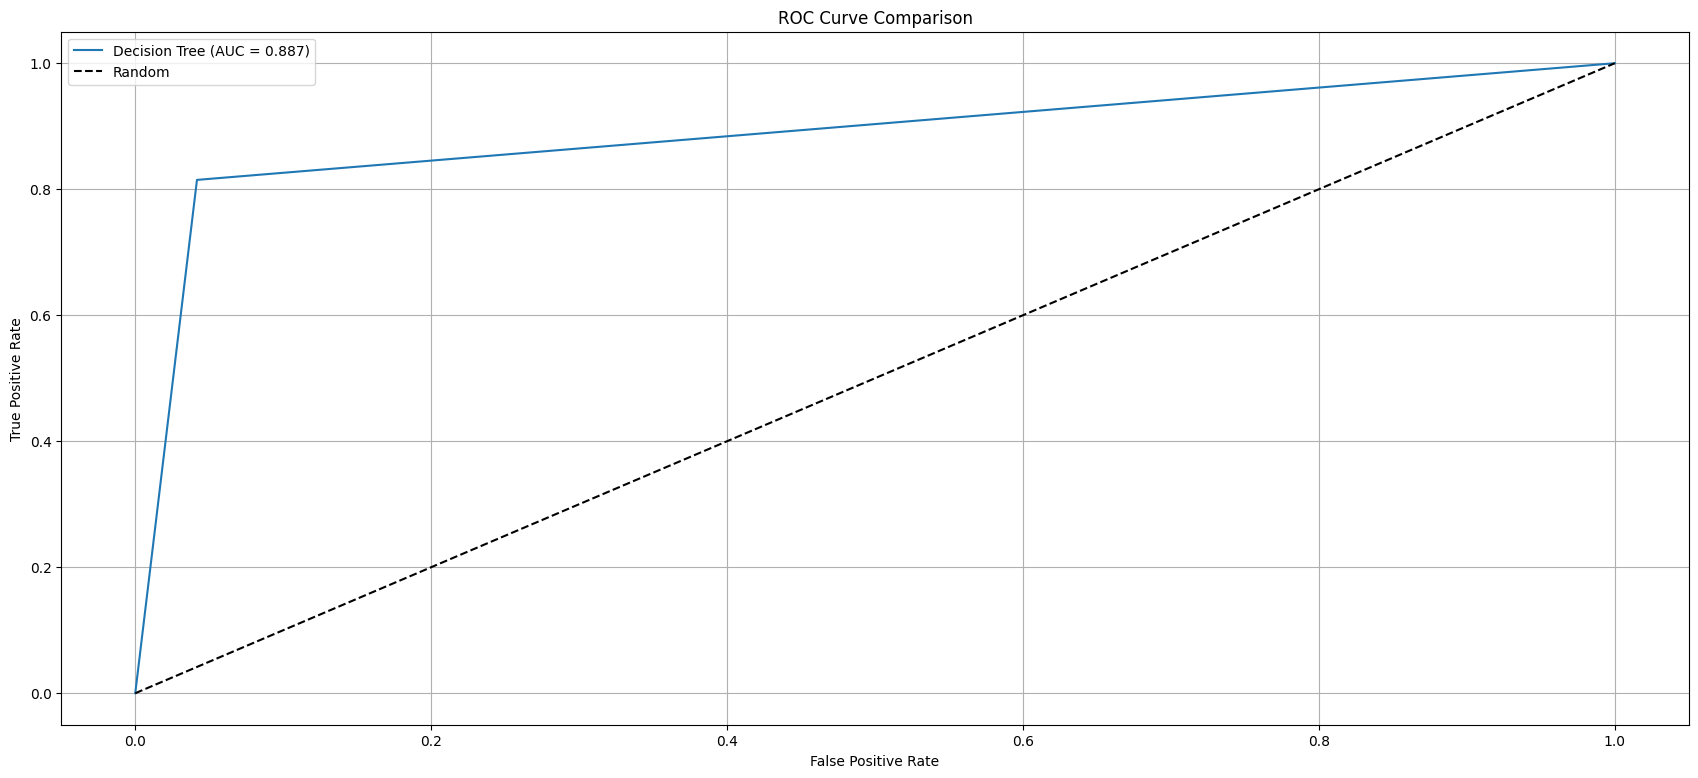

In [ ]:
plot_roc(dt_best, X_test, y_test, 'Decision Tree')

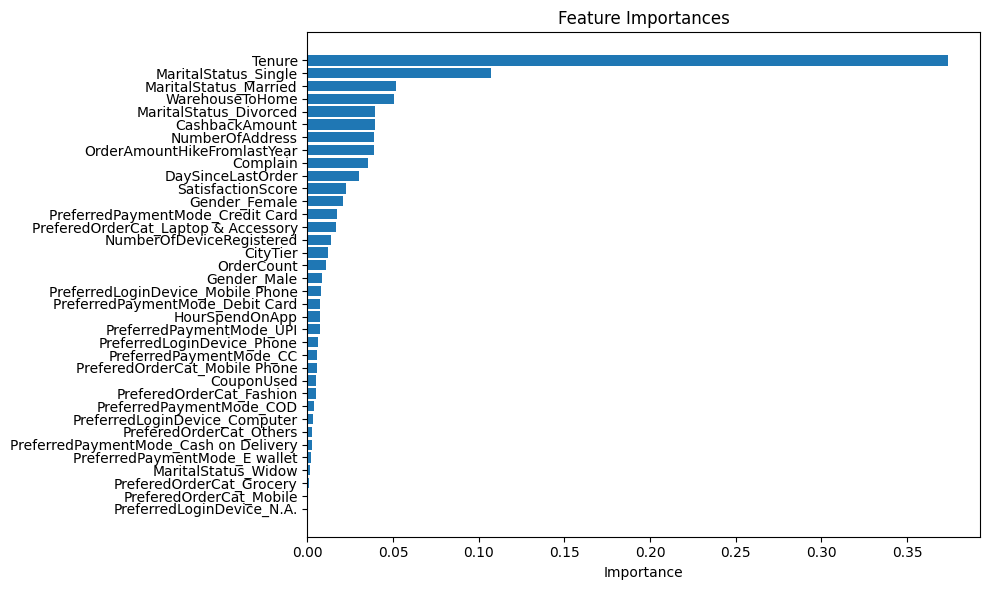

In [ ]:
selected_features_dt = plot_feature_importances(dt_best, X_train)

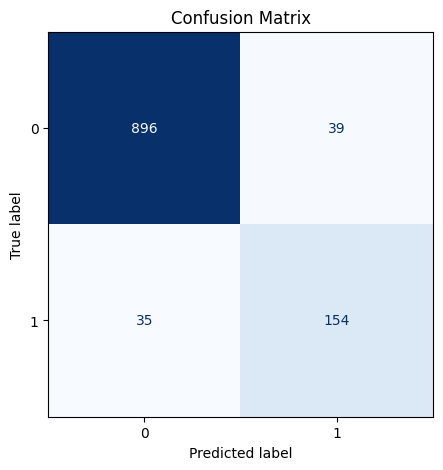

In [ ]:
plot_confusion(y_test, y_pred_dt)

### RANDOM FOREST

In [ ]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

rf = RandomForestClassifier(random_state=42, n_jobs=-1)

grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, n_jobs=-1, scoring='accuracy')

grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
print("Best parameters:", best_params)

rf_best = grid_search.best_estimator_

y_pred_rf = grid_search.predict(X_test)


Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


In [ ]:
scores_rf = pd.DataFrame([compute_scores(rf_best, X_test, y_test, list_scores)], columns=score_names, index=['Random Forest'])
scores_rf

,roc_auc,recall,precision,accuracy
Random Forest,0.99,0.83,0.92,0.96


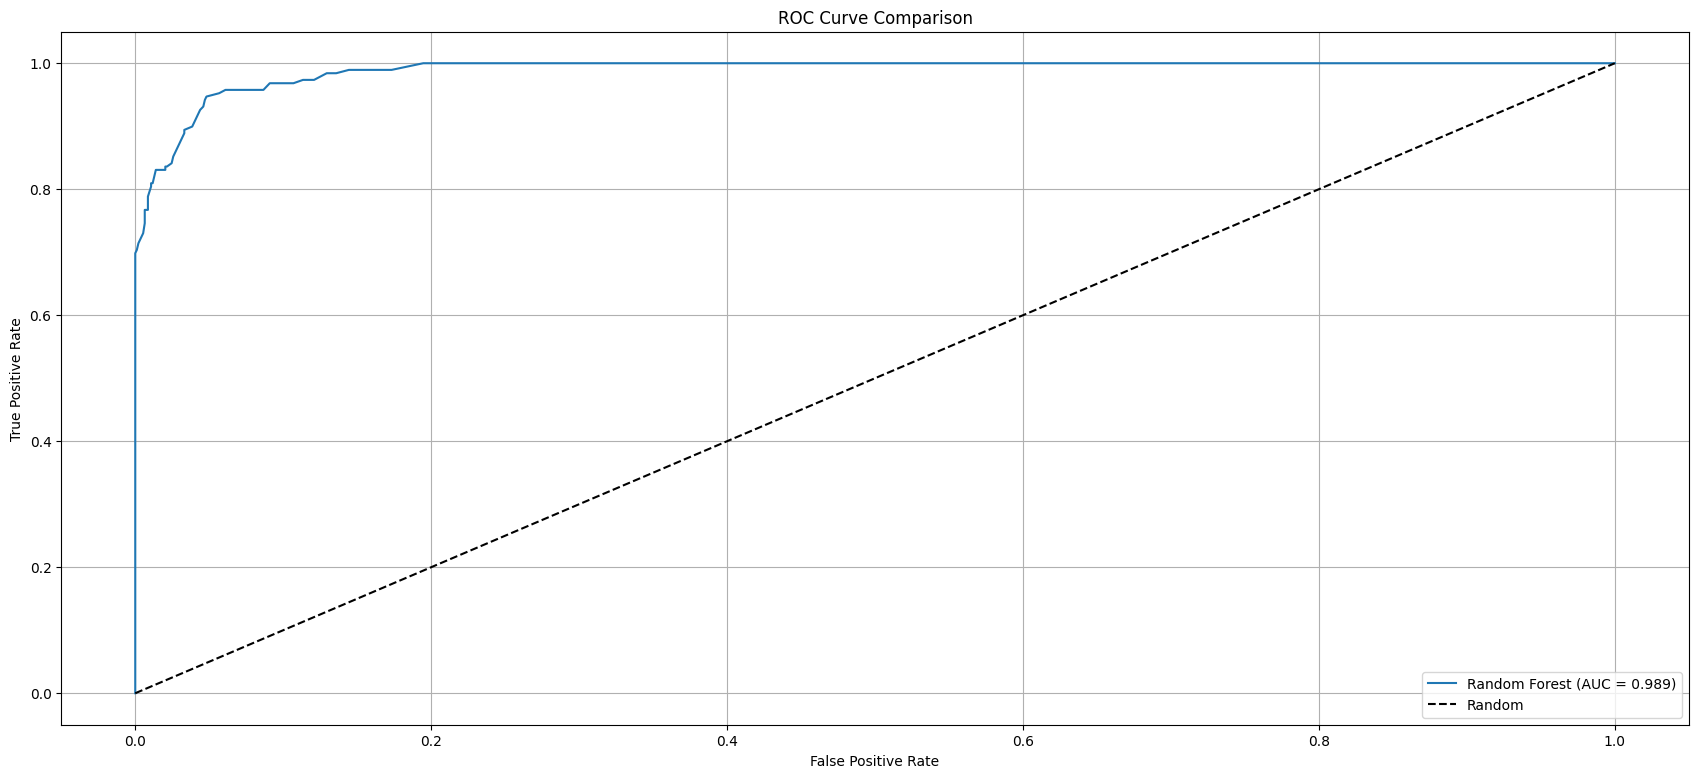

In [ ]:
plot_roc(rf_best, X_test, y_test, 'Random Forest')

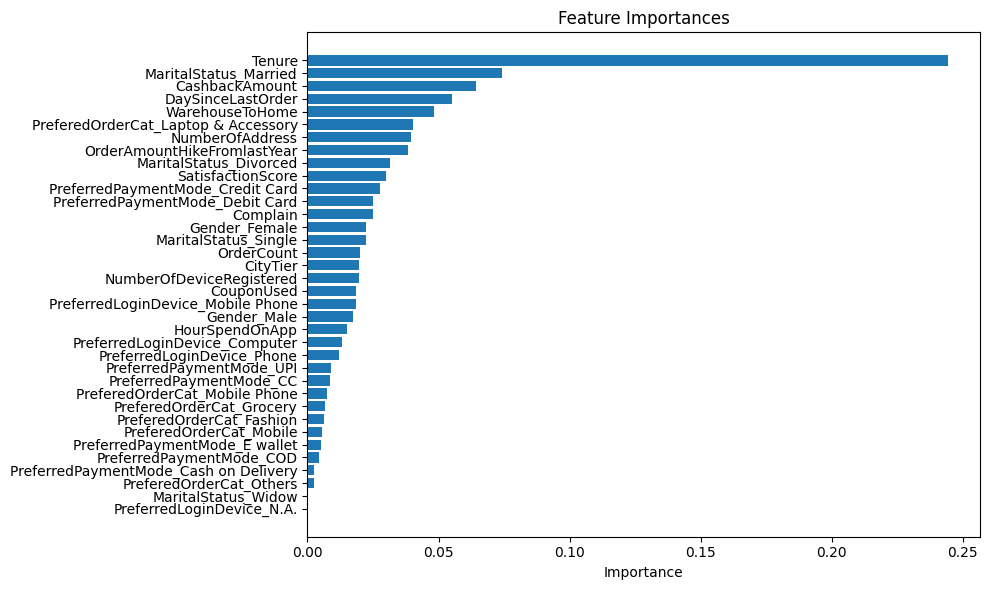

In [ ]:
selected_features_rf = plot_feature_importances(rf_best, X_train)

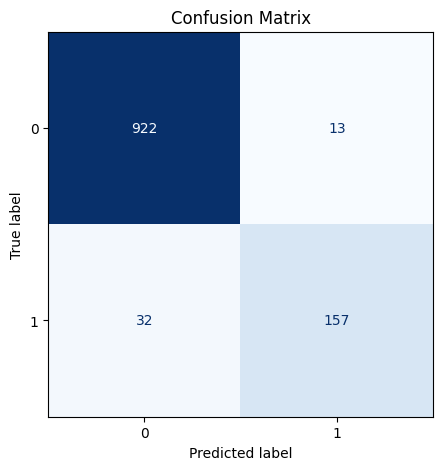

In [ ]:
plot_confusion(y_test, y_pred_rf)

### XGB

In [ ]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 10],
    'learning_rate': [0.01, 0.1, 0.3],
    'subsample': [0.8, 1],
    'colsample_bytree': [0.8, 1]
}

xgb = XGBClassifier(random_state=42, n_jobs=-1, use_label_encoder=False, eval_metric='logloss')

grid_search_xgb = GridSearchCV(estimator=xgb, param_grid=param_grid, cv=5, n_jobs=-1, scoring='accuracy')

grid_search_xgb.fit(X_train, y_train)

best_params_xgb = grid_search_xgb.best_params_
print("Best parameters (XGBoost):", best_params_xgb)

xgb_best = grid_search_xgb.best_estimator_

y_pred_xgb = xgb_best.predict(X_test)

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [18:18:27] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Best parameters (XGBoost): {'colsample_bytree': 0.8, 'learning_rate': 0.3, 'max_depth': 10, 'n_estimators': 200, 'subsample': 1}


In [ ]:
scores_xgb = pd.DataFrame([compute_scores(xgb_best, X_test, y_test, list_scores)], columns=score_names, index=['XGBoost'])
scores_xgb

,roc_auc,recall,precision,accuracy
XGBoost,0.99,0.88,0.95,0.97


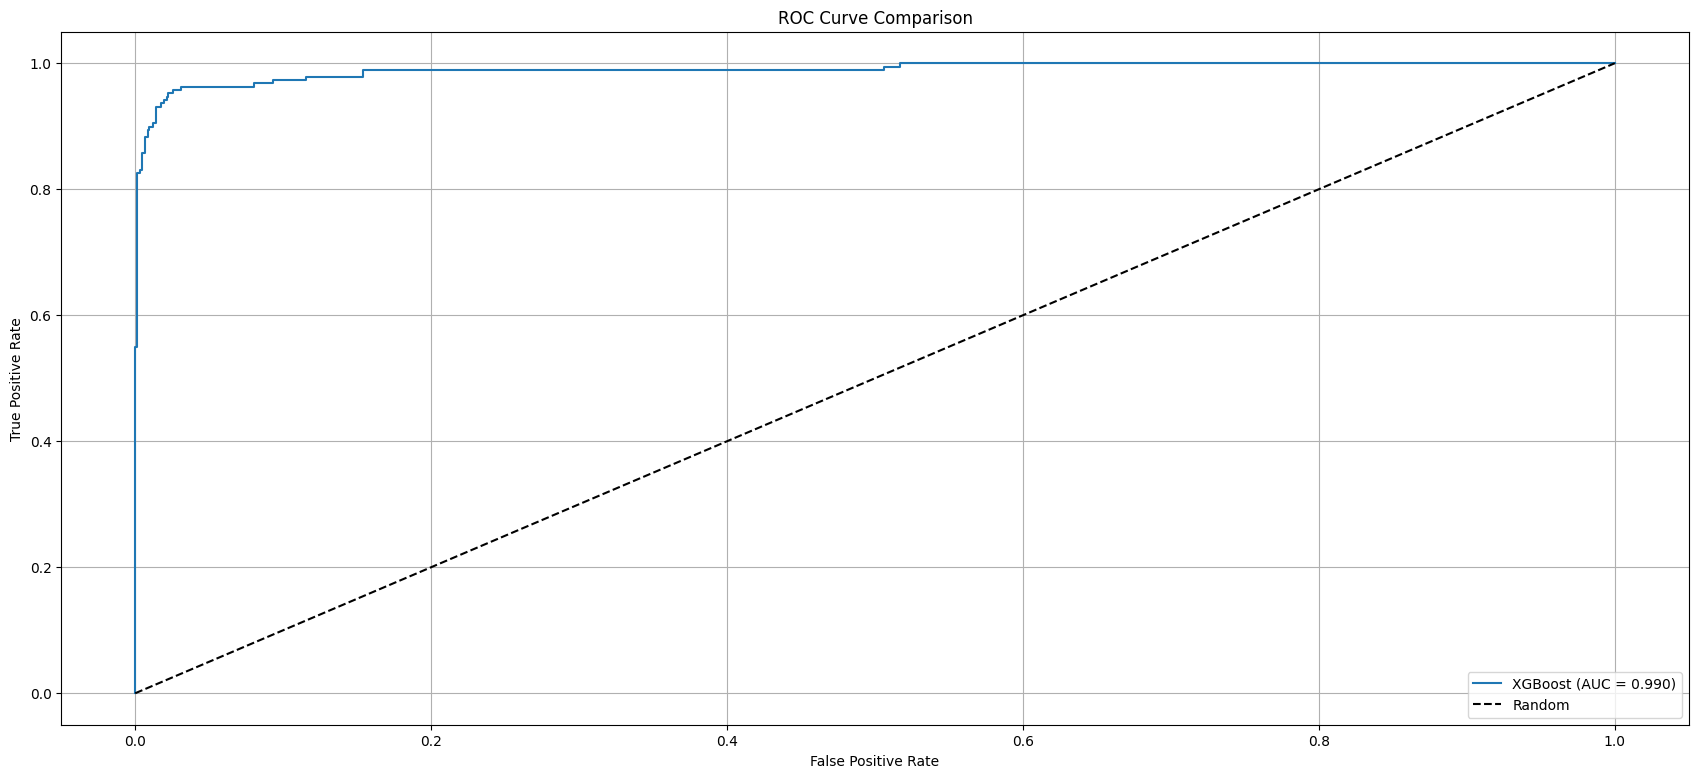

In [ ]:
plot_roc(xgb_best, X_test, y_test, 'XGBoost')

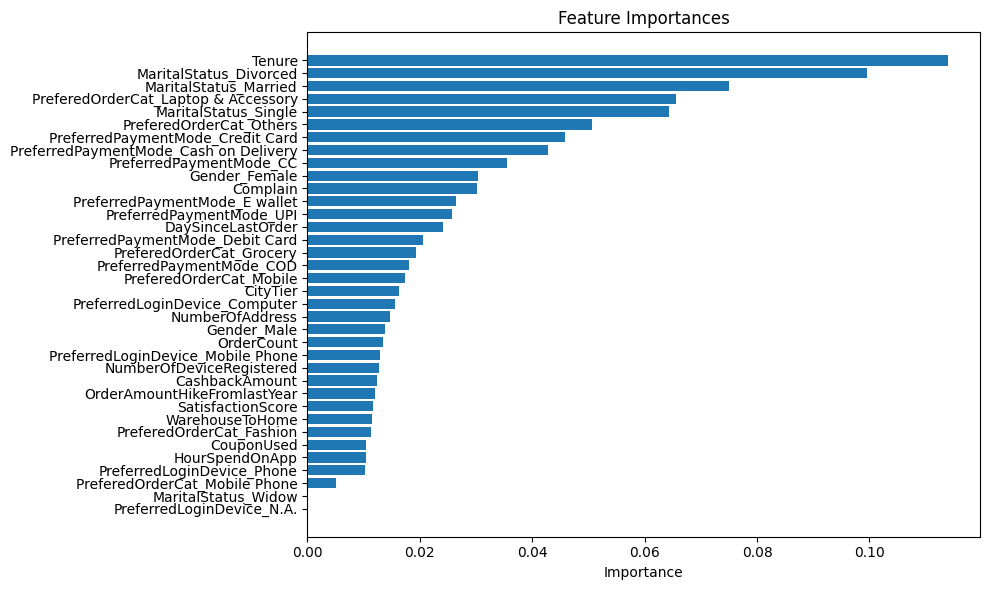

In [ ]:
selected_features_xgb = plot_feature_importances(xgb_best, X_train)

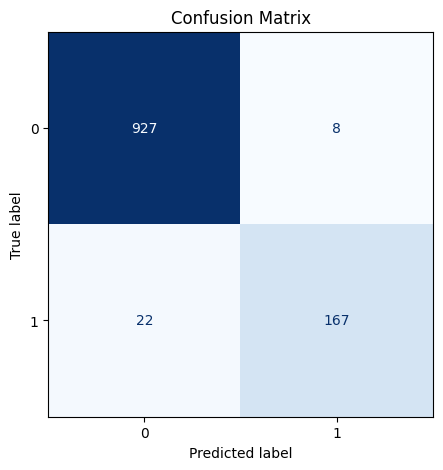

In [ ]:
plot_confusion(y_test, y_pred_xgb)

### CAT BOOSTING

In [ ]:
param_grid = {
    'iterations': [100, 200],
    'depth': [3, 5, 10],
    'learning_rate': [0.01, 0.1, 0.3],
    'l2_leaf_reg': [1, 3, 5]
}

cat = CatBoostClassifier(random_state=42, verbose=0)

grid_search_cat = GridSearchCV(estimator=cat, param_grid=param_grid, cv=5, n_jobs=-1, scoring='accuracy')

grid_search_cat.fit(X_train, y_train)

best_params_cat = grid_search_cat.best_params_
print("Best parameters (CatBoost):", best_params_cat)

cat_best = grid_search_cat.best_estimator_

y_pred_cat = cat_best.predict(X_test)

/usr/local/lib/python3.11/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters (CatBoost): {'depth': 10, 'iterations': 200, 'l2_leaf_reg': 1, 'learning_rate': 0.1}


In [ ]:
scores_cat = pd.DataFrame([compute_scores(cat_best, X_test, y_test, list_scores)], columns=score_names, index=['CatBoost'])
scores_cat

,roc_auc,recall,precision,accuracy
CatBoost,1.0,0.93,0.96,0.98


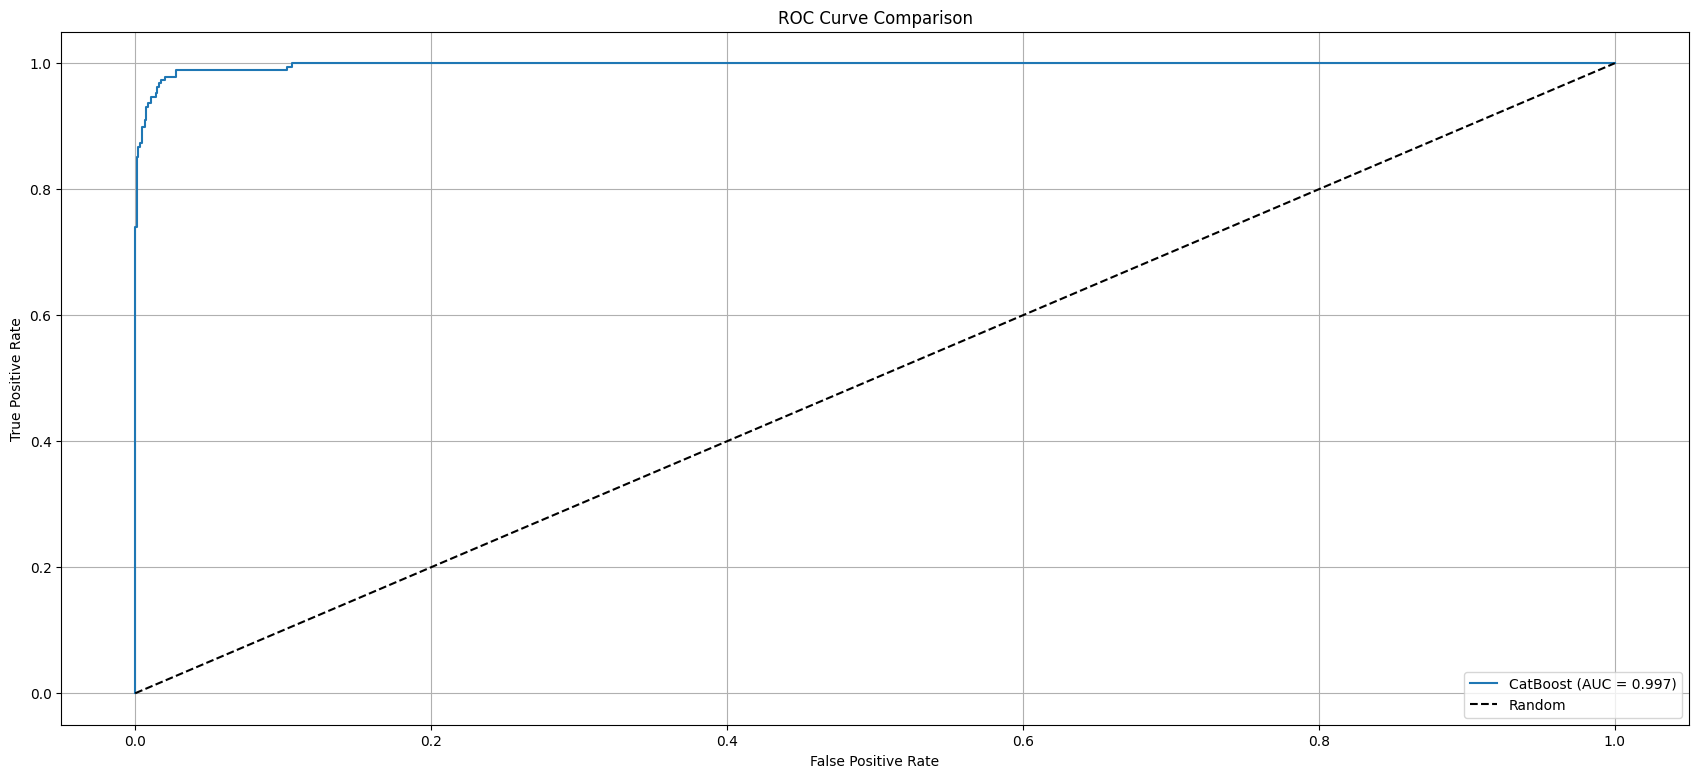

In [ ]:
plot_roc(cat_best, X_test, y_test, 'CatBoost')

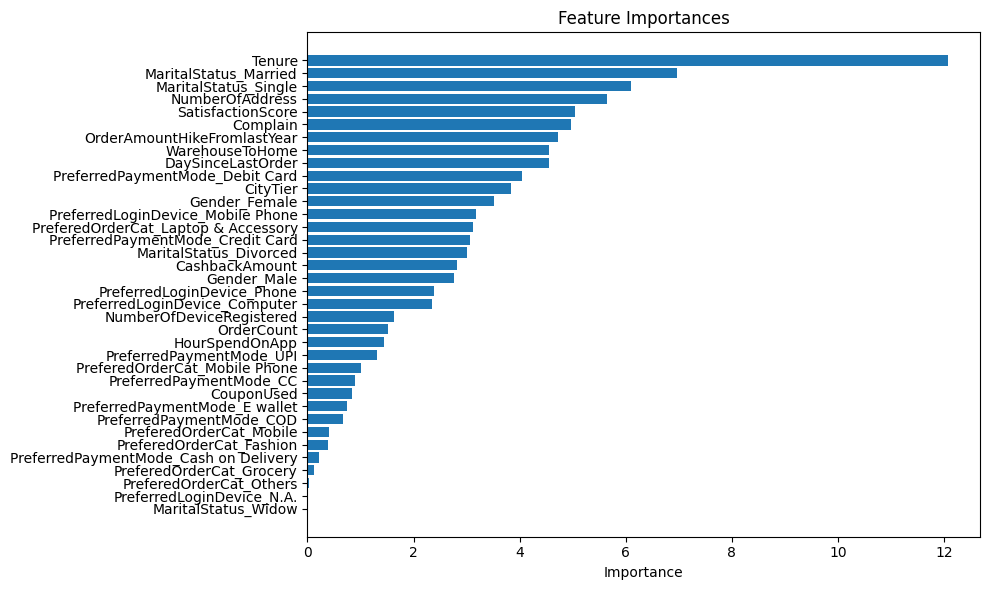

In [ ]:
selected_features_cat = plot_feature_importances(cat_best, X_train)

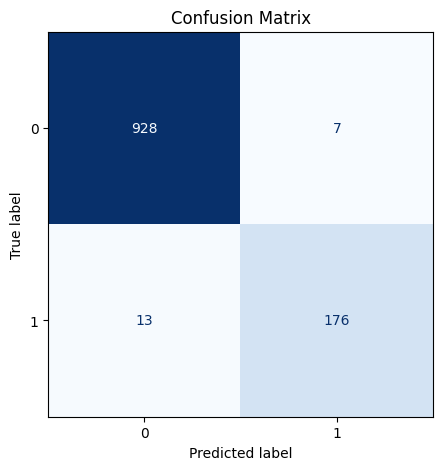

In [ ]:
plot_confusion(y_test, y_pred_cat)

### LOGISTIC REGRESSION

To apply logistic regression, the data need to be scaled; therefore, the following transformation is performed.

In [ ]:
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

In [ ]:
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l2'],
    'solver': ['lbfgs']
}

lr = LogisticRegression(random_state=42, max_iter=1000)

grid_search = GridSearchCV(estimator=lr, param_grid=param_grid, cv=5, n_jobs=-1, scoring='accuracy')

grid_search.fit(X_train_scaled, y_train)

best_params = grid_search.best_params_
print("Best parameters:", best_params)

lr_best = grid_search.best_estimator_

y_pred_lr = grid_search.predict(X_test_scaled)

Best parameters: {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}


In [ ]:
scores_lr = pd.DataFrame([compute_scores(lr_best, X_test_scaled, y_test, list_scores)], columns=score_names, index=['Logistic Regression'])
scores_lr

,roc_auc,recall,precision,accuracy
Logistic Regression,0.89,0.65,0.67,0.89


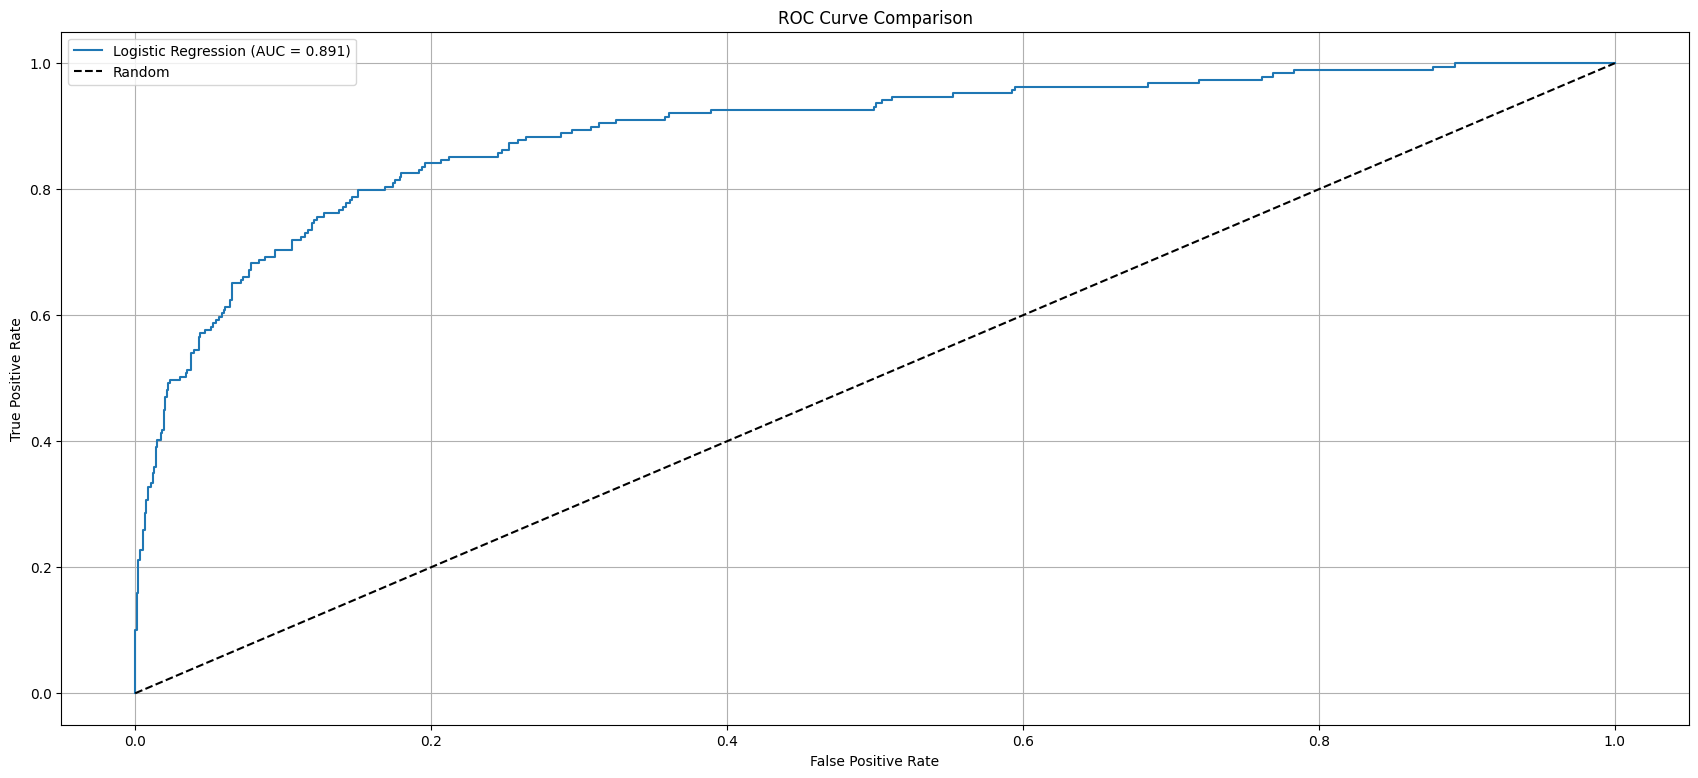

In [ ]:
plot_roc(lr_best, X_test_scaled, y_test, 'Logistic Regression')

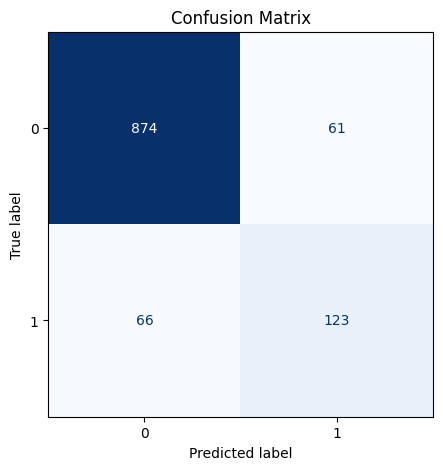

In [ ]:
plot_confusion(y_test, y_pred_lr)

Since logistic regression models don’t provide a `model.feature_importances_`  attribute, we can’t use the original `plot_feature_importances` function.
Instead, we need to write a new one that computes importance from the model’s coefficients.

In [ ]:
column_mapping = {}
for i, col in enumerate(X_train.columns):
    column_mapping[col] = i

In [ ]:
def plot_logistic_regression_importances(model, X_train, column_mapping, top_n_base_names=5):

    feature_names = [col for col, idx in sorted(column_mapping.items(), key=lambda x: x[1])]

    if model.coef_.shape[0] == 1:
        importances = np.abs(model.coef_[0])
    else:
        importances = np.max(np.abs(model.coef_), axis=0)

    sorted_indices = np.argsort(importances)

    plt.figure(figsize=(10, 8))
    plt.title("Feature Importances")
    plt.barh(range(len(importances)), importances[sorted_indices], align='center')
    plt.yticks(range(len(importances)), [feature_names[i] for i in sorted_indices])
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

    selected_base_names = []
    seen = set()
    for i in sorted_indices[::-1]:
        full_name = feature_names[i]
        base_name = full_name.split('_', 1)[0]
        if base_name not in seen:
            selected_base_names.append(base_name)
            seen.add(base_name)
        if len(selected_base_names) >= top_n_base_names:
            break

    return selected_base_names


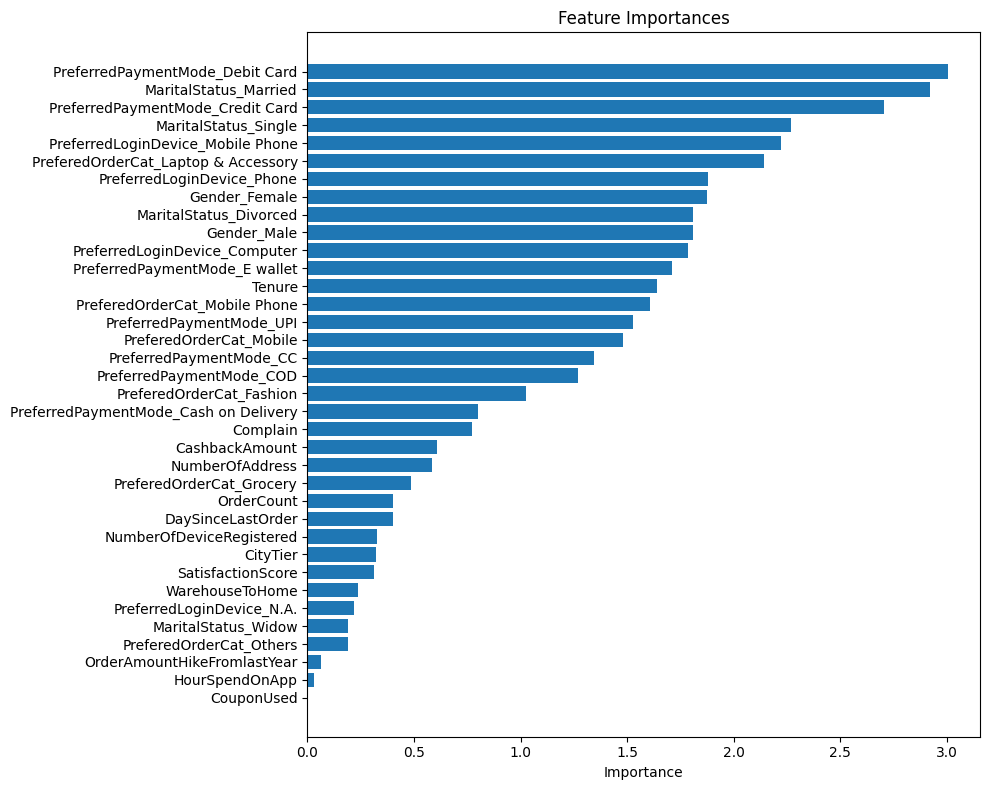

In [ ]:
selected_features_lr = plot_logistic_regression_importances(lr_best, X_train_scaled, column_mapping)

### Multi-Layer Perceptron (MLP) - Neural Network

To apply the Multi-Layer Perceptron (MLP), the data must also be scaled; therefore, the previously scaled data (`X_train_scaled` and `X_test_scaled`) are used.

In [ ]:
def build_model(units_per_layer, num_hidden_layers, lr, dropout):

    input_combined = Input(shape=(X_train_scaled.shape[1],), name='combined_input')

    # First layer
    x = Dense(units_per_layer, activation='sigmoid')(input_combined)
    x = Dropout(dropout)(x)

    # Layers
    for _ in range(num_hidden_layers - 1):
        units_per_layer = max(1, units_per_layer // 2)
        x = Dense(units_per_layer, activation='sigmoid')(x)
        x = Dropout(dropout)(x)

    # Output layer
    output = Dense(1, activation='sigmoid')(x)

    # Model
    model = Model(inputs=input_combined, outputs=output)
    model.compile(optimizer=Adam(learning_rate=lr), loss='binary_crossentropy', metrics=['accuracy'])

    return model

In [ ]:
param_grid = {
    'model__units_per_layer': [32, 64],
    'model__num_hidden_layers': [1, 2, 3],
    'model__lr': [0.001, 0.0001],
    'model__dropout': [0.1, 0.2],
    'batch_size': [16, 32],
}


model = KerasClassifier(model=build_model, epochs=10, verbose=1)

grid = GridSearchCV(estimator=model, param_grid=param_grid, cv=3, n_jobs=-1)

grid_result = grid.fit(X_train_scaled, y_train)

print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))
means = grid_result.cv_results_['mean_test_score']
params = grid_result.cv_results_['params']

/usr/local/lib/python3.11/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Epoch 1/10
234/234 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.5768 - loss: 0.6829
Epoch 2/10
234/234 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8647 - loss: 0.3687
Epoch 3/10
234/234 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8922 - loss: 0.2785
Epoch 4/10
234/234 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9036 - loss: 0.2567
Epoch 5/10
234/234 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9012 - loss: 0.2563
Epoch 6/10
234/234 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9067 - loss: 0.2433
Epoch 7/10
234/234 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9020 - loss: 0.2430
Epoch 8/10
234/234 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9018 - loss: 0.2429
Epoch 9/10
234/234 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9057 - loss: 0.2364
Epoch 10/10
234/234 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9112 - loss: 0.2221
Best: 0.896100 using {'batch_size': 32, 'model__dropout': 0.1, 'model__lr': 0.001, 'model__num_hidden_layers': 3, 'model__units_per_layer'

In [ ]:
best_model = grid_result.best_estimator_.model_
best_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ combined_input (InputLayer)     │ (None, 36)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,981 (58.52 KB)

 Trainable params: 4,993 (19.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,988 (39.02 KB)

In [ ]:
mlp_best = grid.best_estimator_
y_pred_mlp = mlp_best.predict(X_test_scaled)

metrics = {
    'roc_auc':    roc_auc_score(y_test, y_pred_mlp),
    'recall':     recall_score(y_test, y_pred_mlp),
    'precision':  precision_score(y_test, y_pred_mlp),
    'accuracy':   accuracy_score(y_test, y_pred_mlp)
}

scores_mlp = pd.DataFrame(metrics, index=['Multi-Layer Perceptron'])

scores_mlp

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


,roc_auc,recall,precision,accuracy
Multi-Layer Perceptron,0.773302,0.592593,0.722581,0.893238


36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


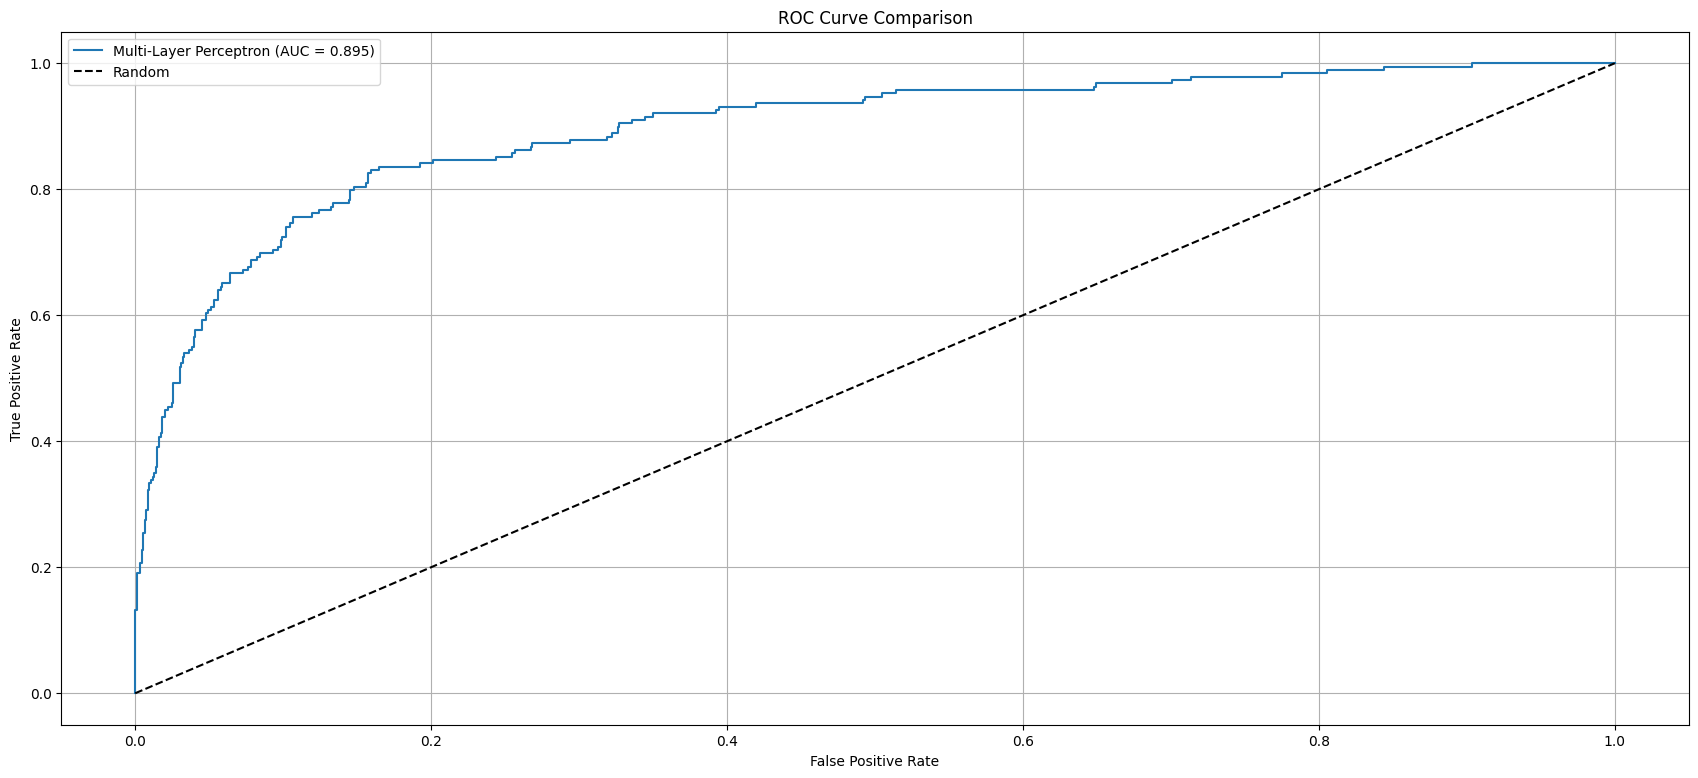

In [ ]:
plot_roc(mlp_best, X_test_scaled, y_test, 'Multi-Layer Perceptron')

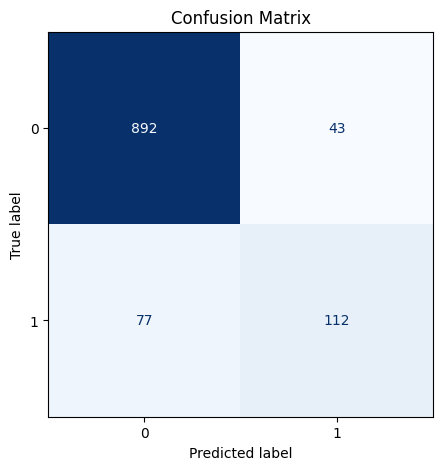

In [ ]:
plot_confusion(y_test, y_pred_mlp)

Since neural networks like MLP don’t provide built-in feature importance attributes, we can’t directly use `.coef_` or `.feature_importances_`.
Instead, we use **permutation importance**, which evaluates how the model's performance drops when each feature is randomly shuffled. 
The `plot_mlp_importance` function computes and visualizes this using the test set, allowing us to identify and plot the most influential features.

In [ ]:
def plot_mlp_importance(model, X_train_df, X_test_scaled, y_test, top_n_base_names=5):

    result = permutation_importance(
        model,
        X_test_scaled,
        y_test,
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    feature_names = X_train_df.columns.tolist()
    importances = result.importances_mean
    sorted_indices = np.argsort(importances)

    plt.figure(figsize=(10, 8))
    plt.title("Feature Importances")
    plt.barh(range(len(importances)), importances[sorted_indices], align='center')
    plt.yticks(range(len(importances)), [feature_names[i] for i in sorted_indices])
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

    selected_base_names = []
    seen = set()
    for i in sorted_indices[::-1]:
        full_name = feature_names[i]
        base_name = full_name.split('_', 1)[0]
        if base_name not in seen:
            selected_base_names.append(base_name)
            seen.add(base_name)
        if len(selected_base_names) >= top_n_base_names:
            break

    return selected_base_names

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


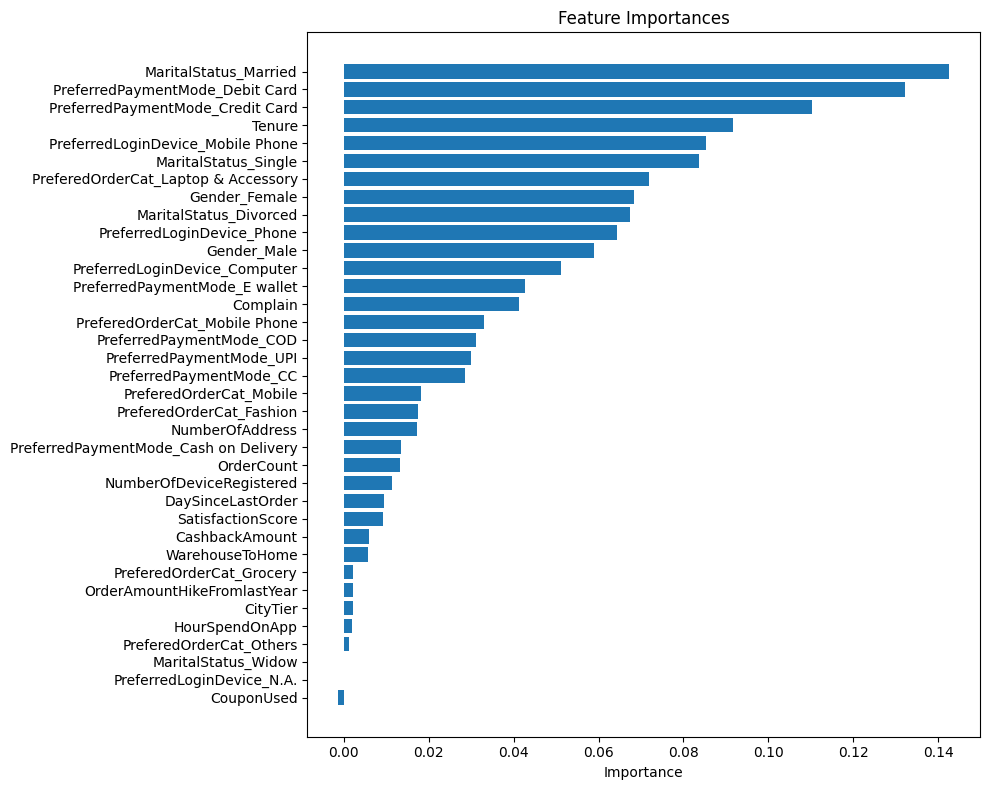

In [ ]:
selected_features_mlp = plot_mlp_importance(mlp_best, X_train, X_test_scaled, y_test)

## **FINAL EVALUATION**

For the final evaluation to identify the best churn model, the classifiers were compared using **ROC curves** and the key **performance metrics**: roc_auc, recall, precision, and accuracy.

### ROC Curve Analysis for All Models

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


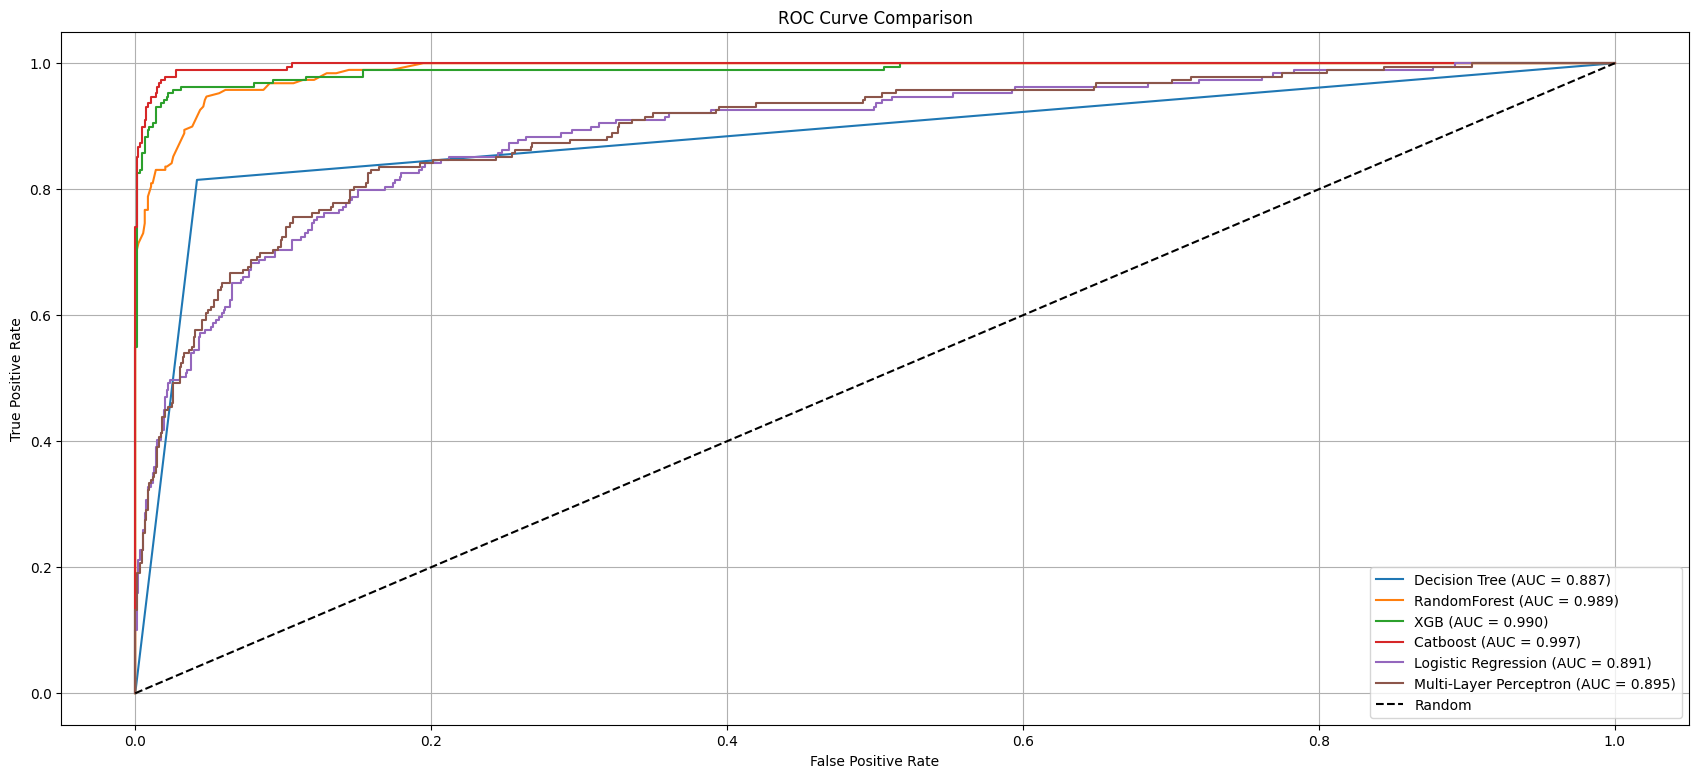

In [ ]:
models_list = [dt_best, rf_best, xgb_best, cat_best, lr_best, mlp_best]
model_names = ['Decision Tree', 'RandomForest', 'XGB', 'Catboost', 'Logistic Regression', 'Multi-Layer Perceptron']
X_tests = [X_test, X_test, X_test, X_test, X_test_scaled, X_test_scaled]

plot_roc(models_list, X_tests, y_test, model_names)

### Evaluation Scores for All Models

In [ ]:
scores_fin = pd.concat([
    scores_dt,
    scores_rf,
    scores_xgb,
    scores_cat,
    scores_lr,
    scores_mlp
], axis=0)


scores_fin

,roc_auc,recall,precision,accuracy
Decision Tree,0.890000,0.810000,0.800000,0.930000
Random Forest,0.990000,0.830000,0.920000,0.960000
XGBoost,0.990000,0.880000,0.950000,0.970000
CatBoost,1.000000,0.930000,0.960000,0.980000
Logistic Regression,0.890000,0.650000,0.670000,0.890000
Multi-Layer Perceptron,0.773302,0.592593,0.722581,0.893238


The comparison of ROC curves and quantitative evaluation metrics indicates that **XGBoost** and **CatBoost** are the top-performing models, with **CatBoost** marginally outperforming **XGBoost** in most key metrics.

### The 5 Most Influential Features per Model



In [ ]:
print("Decision Tree: ", selected_features_dt)
print("Random Forest: ", selected_features_rf)
print("XGBoost: ", selected_features_xgb)
print("CatBoost: ", selected_features_cat)
print("Logistic Regression: ", selected_features_lr)
print("Multi-Layer Perceptron: ", selected_features_mlp)

Decision Tree:  ['Tenure', 'MaritalStatus', 'WarehouseToHome', 'CashbackAmount', 'NumberOfAddress']
Random Forest:  ['Tenure', 'MaritalStatus', 'CashbackAmount', 'DaySinceLastOrder', 'WarehouseToHome']
XGBoost:  ['Tenure', 'MaritalStatus', 'PreferedOrderCat', 'PreferredPaymentMode', 'Gender']
CatBoost:  ['Tenure', 'MaritalStatus', 'NumberOfAddress', 'SatisfactionScore', 'Complain']
Logistic Regression:  ['PreferredPaymentMode', 'MaritalStatus', 'PreferredLoginDevice', 'PreferedOrderCat', 'Gender']
Multi-Layer Perceptron:  ['MaritalStatus', 'PreferredPaymentMode', 'Tenure', 'PreferredLoginDevice', 'PreferedOrderCat']
